<div style="border: 3px solid #0d3b0d; border-radius: 10px; overflow: hidden; margin-bottom: 20px; font-family: Arial, sans-serif;">

  <!-- Banner Institucional -->
  <div style="background-color: #006633; padding: 0;">
    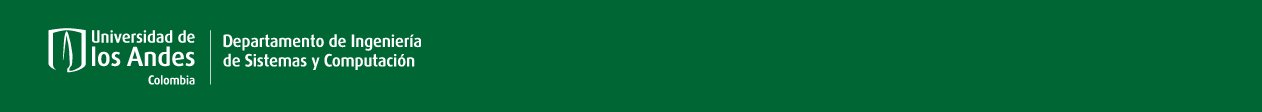
  </div>

  <!-- Titulo del laboratorio -->
  <div style="background-color: #ffffff; padding: 15px 20px; text-align: center;">
    <h2 style="margin: 0; color: #1a1a1a; font-size: 18px;">AI Security - Laboratorio 5 · Sesión 11</h2>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 13px;">Ataque de Inferencia de Membresía (Membership Inference Attack)</p>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 12px;">Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI)</p>
  </div>

  <!-- Aviso de propiedad intelectual -->
  <div style="background-color: #f5f5f0; padding: 12px 20px; border-top: 1px solid #ddd; font-size: 11px; color: #444; line-height: 1.5;">
    <strong>Propiedad Intelectual - Universidad de los Andes</strong><br>
    Este material es propiedad exclusiva de la Universidad de los Andes (Bogot&aacute;, Colombia) y ha sido desarrollado para el programa de Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI), Departamento de Ingenier&iacute;a de Sistemas y Computaci&oacute;n. Todos los derechos reservados &copy; 2026.<br><br>
    <strong>Condiciones de uso:</strong> Este material se distribuye exclusivamente a los estudiantes matriculados en el curso AI Security del programa MESI y est&aacute; protegido por las leyes colombianas de derechos de autor (Ley 23 de 1982 y Ley 1915 de 2018) y por las disposiciones aplicables de propiedad intelectual de la Universidad de los Andes. Queda estrictamente prohibida su reproducci&oacute;n, distribuci&oacute;n, modificaci&oacute;n, publicaci&oacute;n o transmisi&oacute;n total o parcial, en cualquier forma o medio, sin la autorizaci&oacute;n previa y por escrito de la Universidad de los Andes. El incumplimiento de estas condiciones podr&aacute; dar lugar a las acciones disciplinarias, civiles y penales correspondientes.
  </div>

</div>

# **Laboratorio 5 · Sesión 11: Ataque de Inferencia de Membresía (Membership Inference Attack)**

**Curso:** AI Security - MESI    


## **Objetivos de Aprendizaje**

Al completar este laboratorio, el estudiante será capaz de:

1. Comprender qué son los ataques de inferencia de membresía (MIA) y su impacto en la privacidad de modelos de ML
2. Analizar las distribuciones de confianza de un modelo para distinguir entre datos de entrenamiento y datos no vistos
3. Implementar un ataque basado en métricas (threshold attack) de forma manual
4. Construir un ataque con shadow models siguiendo la metodología de Shokri et al. (2017)
5. Validar los resultados utilizando la libreria ART (Adversarial Robustness Toolbox)
6. Evaluar cómo el overfitting del modelo víctima influye en la vulnerabilidad a MIA

---

## **Aviso Legal y Uso de Datos**

### **Propósito Académico**

Este laboratorio se desarrolla exclusivamente con **fines académicos y educativos** en el marco del curso de AI Security de la Maestría en Seguridad de la Información (MESI) de la Universidad de los Andes. El contenido, técnicas y herramientas presentadas están diseñadas para la enseñanza de conceptos de Machine Learning aplicados a ciberseguridad.

### **Datos Utilizados**

El dataset empleado en este laboratorio es de **uso libre y público**:

- **CIFAR-10:** Dataset de imágenes de 10 clases, incluido nativamente en TensorFlow/Keras
  - Licencia: Uso libre para investigacion y educacion
  - Fuente: Canadian Institute For Advanced Research
  - Referencia: Krizhevsky, A. (2009). Learning Multiple Layers of Features from Tiny Images. Technical Report, University of Toronto.

### **Consideraciones Éticas**

- Los ataques de inferencia de membresía representan una amenaza real a la privacidad de datos sensibles (registros médicos, financieros, etc.)
- Las técnicas aquí presentadas deben utilizarse únicamente para **evaluar y mejorar** la privacidad de modelos de ML
- El uso indebido de estas técnicas para violar la privacidad de terceros es responsabilidad exclusiva del usuario
- Este material se rige por las políticas academicas de la Universidad de los Andes

---

## **Metodología: Ciclo CRISP-DM**

Este laboratorio sigue la metodología **CRISP-DM (Cross-Industry Standard Process for Data Mining)**, adaptada al contexto de un ataque de privacidad:

1. **Comprensión del Negocio (Business Understanding):** Entender la amenaza de inferencia de membresía y su impacto en la confidencialidad
2. **Comprensión de los Datos (Data Understanding):** Explorar CIFAR-10, comprender la division miembros/no-miembros
3. **Preparación de los Datos (Data Preparation):** Configurar particiones para modelo víctima, shadow models y evaluacion del ataque
4. **Modelado (Modeling):** Entrenar modelo víctima, implementar ataques (métricas, shadow models, ART)
5. **Evaluación (Evaluation):** Medir efectividad del ataque con accuracy, precision, recall, ROC-AUC
6. **Despliegue (Deployment):** Discutir contramedidas y defensas (Differential Privacy, regularización)

A medida que avance en el laboratorio, identifique en que fase de CRISP-DM se encuentra en cada sección.

## **Contexto: Ataques de Inferencia de Membresía (MIA)**

### **¿Qué es un Membership Inference Attack?**

Un **ataque de inferencia de membresía** busca determinar si un registro de datos específico fue utilizado para entrenar un modelo de Machine Learning. Formalmente, dado un modelo entrenado $f$ y un punto de datos $(x, y)$, el atacante intenta inferir si $(x, y) \in D_{train}$.

### **¿Por qué funcionan estos ataques?**

Los modelos de ML tienden a **memorizar** patrones de sus datos de entrenamiento, lo que se manifiesta en:

- **Mayor confianza** en predicciones sobre datos de entrenamiento (miembros) vs. datos no vistos (no-miembros)
- **Menor pérdida (loss)** en datos de entrenamiento que en datos de prueba
- **Overfitting**: cuanto mayor es la brecha de generalización (gap entre train y test accuracy), más vulnerable es el modelo

### **¿Por qué son peligrosos?**

- **Privacidad medica:** Inferir que un registro clínico fue usado para entrenar un modelo de diagnostico de cancer revela que el paciente tiene (o tuvo) cancer
- **Datos financieros:** Determinar que una transaccion fue parte del entrenamiento de un detector de fraude revela información sensible
- **Cumplimiento normativo:** Violaciones de GDPR, CCPA y otras regulaciones de proteccion de datos

### **Taxonomia de ataques MIA**

Segun la clasificación de Hu et al. (2022), los MIA se categorizan por el conocimiento del adversario:

- **Caja negra (Black-box):** El atacante solo tiene acceso a las predicciones del modelo (probabilidades o etiquetas)
- **Caja blanca (White-box):** El atacante tiene acceso a los parámetros internos del modelo
- **Basados en shadow models:** El atacante entrena modelos sustitutos para simular el comportamiento del modelo víctima (Shokri et al., 2017)
- **Basados en métricas:** El atacante usa umbrales sobre métricas de confianza sin necesidad de entrenar modelos adicionales (Yeom et al., 2018)

### **Conexión con MITRE ATLAS**

Los ataques de inferencia de membresía estan catalogados en el framework MITRE ATLAS como parte de las tacticas de **ML Model Access** y **Exfiltration**, representando una amenaza directa a la confidencialidad de los datos de entrenamiento.

### **Para profundizar sobre MIA:**
- [Shokri et al. (2017) - Membership Inference Attacks Against Machine Learning Models](https://www.cs.cornell.edu/~shmat/shmat_oak17.pdf) - Paper seminal, IEEE S&P 2017
- [Hu et al. (2022) - Membership Inference Attacks on Machine Learning: A Survey](https://dl.acm.org/doi/10.1145/3523273) - ACM Computing Surveys
- [MITRE ATLAS - Inference Attacks](https://atlas.mitre.org/) - Framework de referencia

---

## **1. Configuración del Entorno**

Instalamos las librerias necesarias para este laboratorio.

In [ ]:
import os
import sys

# Agrega la ruta de ejecutables y paquetes locales al PATH y sys.path del sistema
local_bin = os.path.expanduser("~/.local/bin")
if local_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{local_bin}:{os.environ['PATH']}"

user_site = os.path.expanduser("~/.local/lib/python3.10/site-packages")
if user_site not in sys.path:
    sys.path.append(user_site)

# transformer_engine, torchvision y torchaudio (preinstalados en la imagen del servidor)
# no son compatibles con su PyTorch y rompen importaciones en cadena. Este laboratorio no
# los usa: se marcan como no disponibles antes de importar cualquier libreria.
for _m in ("transformer_engine", "transformer_engine_extensions", "torchvision", "torchaudio"):
    sys.modules[_m] = None

In [ ]:
# Instalacion de dependencias SIN reemplazar TensorFlow / PyTorch / NumPy del servidor.
# El servidor trae builds especiales de TensorFlow y PyTorch compilados para su driver de
# GPU (CUDA 12.4). Un `pip install tensorflow` instala en ~/.local una version mas nueva
# que no ve la GPU (o no carga). Esta celda:
#   1) comprueba en un proceso aparte que TensorFlow vea la GPU;
#   2) si no la ve, quita de ~/.local el TensorFlow/PyTorch que tapa al del servidor;
#   3) instala solo lo que falta (ART, scikit-learn, ...) fijando las versiones del servidor.
import os, sys, subprocess
from importlib.metadata import distributions

USER_SITE = os.path.expanduser("~/.local/lib/python3.10/site-packages")
PIP = [sys.executable, "-m", "pip"]
PROBE = ("import os; os.environ['TF_CPP_MIN_LOG_LEVEL']='3'; import tensorflow as tf; "
         "print('TFPROBE', tf.__version__, '|', tf.__file__, '|', "
         "len(tf.config.list_physical_devices('GPU')))")

def probar_tensorflow():
    r = subprocess.run([sys.executable, "-c", PROBE], capture_output=True, text=True)
    for linea in r.stdout.splitlines():
        if linea.startswith("TFPROBE"):
            ver, ruta, ngpu = [s.strip() for s in linea[len("TFPROBE"):].split("|")]
            return {"version": ver, "ruta": ruta, "gpus": int(ngpu)}, ""
    return None, r.stderr[-2500:]

def paquetes_user_site():
    if not os.path.isdir(USER_SITE):
        return {}
    return {(d.metadata["Name"] or "").lower(): d.version for d in distributions(path=[USER_SITE])}

def desinstalar(nombres):
    if nombres:
        print("Desinstalando de ~/.local:", nombres)
        subprocess.run(PIP + ["uninstall", "-y", "-q", *nombres], check=False)

info, err = probar_tensorflow()
print("TensorFlow detectado:", info)

if info is None or info["gpus"] == 0:
    # Paso 2: quitar de ~/.local la pila TF/PyTorch que sustituye a la del servidor
    pref = ("tensorflow", "tf-keras", "tf_keras", "keras", "tensorboard", "nvidia-", "ml-dtypes", "ml_dtypes")
    desinstalar(sorted(n for n in paquetes_user_site()
                       if n.startswith(pref) or n in {"torch", "torchvision", "torchaudio", "triton"}))
    info, err = probar_tensorflow()
    # Un NumPy 2.x en ~/.local tambien impide cargar el TensorFlow del servidor
    if info is None and "numpy" in err.lower() and "numpy" in paquetes_user_site():
        desinstalar(["numpy"])
        info, err = probar_tensorflow()
    print("TensorFlow tras la limpieza:", info)

if info is None or info["gpus"] == 0:
    print(err)
    raise RuntimeError(
        "TensorFlow no detecta la GPU. Ejecute en una celda:\n"
        "  !nvidia-smi; pip list --user | grep -i -E 'tensorflow|keras|numpy|nvidia|torch'\n"
        "y comparta la salida.")

# Paso 3: fijar las versiones del servidor y instalar el resto
FIJAR = {"tensorflow", "keras", "tf-keras", "numpy", "torch", "ml-dtypes", "tensorboard", "protobuf", "h5py"}
freeze = subprocess.run(PIP + ["list", "--format=freeze"], capture_output=True, text=True).stdout
RESTRICCIONES = os.path.expanduser("~/lab5_constraints.txt")
with open(RESTRICCIONES, "w") as f:
    for linea in freeze.splitlines():
        if "==" in linea and linea.split("==")[0].lower() in FIJAR:
            f.write(linea + "\n")
print("Versiones fijadas:\n" + open(RESTRICCIONES).read())

subprocess.run(PIP + ["install", "-q", "--user", "-c", RESTRICCIONES,
                      "scikit-learn", "matplotlib", "seaborn", "pandas", "scipy",
                      "adversarial-robustness-toolbox"], check=True)

info, err = probar_tensorflow()
print("Verificacion final:", info)
if info is None or info["gpus"] == 0:
    print(err)
    raise RuntimeError("La instalacion dejo a TensorFlow sin GPU; comparta esta salida.")
print("\nListo. Reinicie el kernel (Kernel -> Restart) y continue desde la celda 1 "
      "SIN volver a ejecutar esta celda.")

Importaciones

In [ ]:
# Importaciones del laboratorio
import os
import gc
import time
import warnings

# Nivel de logs de TensorFlow (debe fijarse antes de importarlo): 2 = solo errores
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Manejo y visualizacion de datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.special import gammaln, logsumexp

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers

# scikit-learn: division de datos, modelos de ataque y metricas
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             roc_auc_score, accuracy_score, precision_score, recall_score, f1_score)

# Crecimiento dinamico de memoria en GPU: TensorFlow no reserva toda la VRAM de golpe
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"No se pudo habilitar memory growth en {gpu.name}: {e}")

# El laboratorio debe correr en GPU: si TensorFlow no la ve, se detiene aqui
if not gpus:
    raise RuntimeError(
        "TensorFlow no detecta la GPU. Ejecute la celda de instalacion (corrige la "
        "instalacion), reinicie el kernel y vuelva a correr desde la celda 1.")

# Salida limpia
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# Estilo de las visualizaciones
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print(f"TensorFlow: {tf.__version__}  ({tf.__file__})")
print(f"Keras:      {keras.__version__}")
print(f"NumPy:      {np.__version__}")
print(f"GPUs disponibles: {len(gpus)} -> {[g.name for g in gpus]}")

### **Documentación de Librerías:**
Si no estas familiarizado con alguna libreria, consulta:
- [TensorFlow/Keras - Guia oficial](https://www.tensorflow.org/guide)
- [Scikit-learn - User Guide](https://scikit-learn.org/stable/user_guide.html)
- [ART - Documentacion de inferencia](https://adversarial-robustness-toolbox.readthedocs.io/en/latest/modules/attacks/inference/membership_inference.html)
- [Matplotlib - Gallery](https://matplotlib.org/stable/gallery/index.html)

---

## **2. Carga y Comprensión de los Datos**

### **CIFAR-10**

CIFAR-10 es un dataset de referencia en vision por computador que contiene 60,000 imágenes a color de 32x32 pixeles en 10 clases. Lo elegimos para este laboratorio porque:

- Es lo suficientemente complejo para que una CNN presente overfitting (lo cual es deseable para demostrar MIA)
- Es ampliamente utilizado en la literatura de MIA (Shokri et al. 2017, Carlini et al. 2022)
- Esta disponible nativamente en TensorFlow/Keras, sin necesidad de descarga externa
- Permite entrenar modelos en tiempo razonable incluso sin GPU

In [ ]:
# Cargamos CIFAR-10 directamente desde Keras
# El dataset viene pre-dividido en 50,000 imágenes de entrenamiento
# y 10,000 de prueba, con 10 clases balanceadas

(x_full_train, y_full_train), (x_full_test, y_full_test) = tf.keras.datasets.cifar10.load_data()

# Nombres de las 10 clases de CIFAR-10
CLASS_NAMES = ['avion', 'automovil', 'pajaro', 'gato', 'ciervo',
               'perro', 'rana', 'caballo', 'barco', 'camion']

print(f"Datos de entrenamiento: {x_full_train.shape}")
print(f"Datos de prueba: {x_full_test.shape}")
print(f"Rango de pixeles: [{x_full_train.min()}, {x_full_train.max()}]")
print(f"Clases: {len(CLASS_NAMES)}")
print(f"Forma de etiquetas: {y_full_train.shape}")

### **Visualización de Ejemplos**

Visualicemos algunas imágenes del dataset para familiarizarnos con los datos.

In [ ]:
# Visualizar ejemplos de cada clase
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Ejemplos de CIFAR-10 (una imagen por clase)', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    # Encontrar el primer ejemplo de la clase i
    idx = np.where(y_full_train.flatten() == i)[0][0]
    ax.imshow(x_full_train[idx])
    ax.set_title(CLASS_NAMES[i], fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

---

## **3. Preparación de los Datos**

### **Estrategia de Particionamiento**

Para ejecutar un ataque de inferencia de membresía necesitamos particiones cuidadosas de los datos. Dividimos el dataset completo en las siguientes particiones:

- **Datos del modelo víctima:**
  - `x_victim_train` / `y_victim_train`: Datos con los que se entrena el modelo víctima (estos son los **miembros**)
  - `x_victim_test` / `y_victim_test`: Datos que el modelo víctima nunca vio (estos son los **no-miembros**)

- **Datos para shadow models** (usados en la Fase 2):
  - `x_shadow` / `y_shadow`: Pool de datos disponible para entrenar shadow models (disjunto de los datos del víctima)

Esta separación es critica: si los datos del shadow model se solapan con los del víctima, el ataque no seria realista.

In [ ]:
# Normalizamos los pixeles al rango [0, 1]
# Esto es estandar en deep learning para estabilizar el entrenamiento
x_full_train = x_full_train.astype('float32') / 255.0
x_full_test = x_full_test.astype('float32') / 255.0

# Aplanamos las etiquetas de (N, 1) a (N,)
y_full_train = y_full_train.flatten()
y_full_test = y_full_test.flatten()

print(f"Rango de pixeles normalizado: [{x_full_train.min()}, {x_full_train.max()}]")
print(f"Forma de etiquetas: {y_full_train.shape}")

In [ ]:
# Particionamiento de datos
# Usamos 15,000 muestras para el modelo víctima (train) y 15,000 como no-miembros
# Las restantes 20,000 muestras se reservan para los shadow models
# Usamos subsets más pequenos para que el entrenamiento sea rapido en CPU

N_VICTIM = 15000   # Muestras para entrenar el modelo victima
N_NONMEMBER = 15000 # Muestras no-miembro (para evaluar el ataque)

# Mezclar los datos antes de particionar
indices = np.random.permutation(len(x_full_train))
x_shuffled = x_full_train[indices]
y_shuffled = y_full_train[indices]

# Partición 1: Datos del modelo víctima (miembros del entrenamiento)
x_victim_train = x_shuffled[:N_VICTIM]
y_victim_train = y_shuffled[:N_VICTIM]

# Partición 2: No-miembros (datos que el víctima NUNCA ve durante entrenamiento)
x_victim_test = x_shuffled[N_VICTIM:N_VICTIM + N_NONMEMBER]
y_victim_test = y_shuffled[N_VICTIM:N_VICTIM + N_NONMEMBER]

# Partición 3: Pool para shadow models (disjunto de víctima)
x_shadow_pool = x_shuffled[N_VICTIM + N_NONMEMBER:]
y_shadow_pool = y_shuffled[N_VICTIM + N_NONMEMBER:]

print(f"Modelo víctima - Entrenamiento (miembros):  {x_victim_train.shape[0]:,}")
print(f"Modelo víctima - No-miembros:               {x_victim_test.shape[0]:,}")
print(f"Pool para shadow models:                     {x_shadow_pool.shape[0]:,}")
print(f"Datos de prueba originales (reservados):     {x_full_test.shape[0]:,}")
print(f"\nTotal: {x_victim_train.shape[0] + x_victim_test.shape[0] + x_shadow_pool.shape[0]:,}")

### **Verificación de Disjunción**

Es importante verificar que las particiones no se solapan. En nuestro caso, al usar slicing secuencial sobre datos mezclados, la disjunción esta garantizada por construcción.

In [ ]:
# Verificación: los indices son disjuntos por construcción (slicing secuencial)
# Pero validamos la distribución de clases en cada partición

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, data, title in zip(axes,
    [y_victim_train, y_victim_test, y_shadow_pool],
    ['Victima Train (Miembros)', 'No-Miembros', 'Shadow Pool']):
    unique, counts = np.unique(data, return_counts=True)
    ax.bar([CLASS_NAMES[i] for i in unique], counts, color='steelblue', alpha=0.8)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Cantidad')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Distribución de Clases por Partición', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

## **4. Entrenamiento del Modelo Víctima**

### **Diseño Intencional: Un Modelo Vulnerable**

Para demostrar la efectividad de los MIA, entrenamos intencionalmente un modelo CNN **sin técnicas de regularización** (sin Dropout, sin BatchNormalization, sin Data Augmentation). Esto provocará overfitting, que es precisamente lo que hace a un modelo vulnerable a ataques de inferencia de membresía.

Posteriormente (Sección 8), entrenaremos un modelo **con regularización** para comparar la vulnerabilidad y entender cómo las defensas mitigan este tipo de ataque.

**Nota:** Esta decisión de diseño es pedagógica. En un entorno de producción, siempre se deben aplicar técnicas de regularización.

In [ ]:
def build_victim_cnn(input_shape=(32, 32, 3), num_classes=10):
    """
    Construye una CNN simple SIN regularizacion.

    Arquitectura disenada para ser lo suficientemente expresiva como
    para overfittear CIFAR-10, lo cual la hace vulnerable a MIA.

    Parametros:
        input_shape: Forma de las imágenes de entrada
        num_classes: Numero de clases de salida

    Retorna:
        model: Modelo Keras compilado
    """
    model = models.Sequential([
        # Bloque convolucional 1
        layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Bloque convolucional 2
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Clasificador
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Construir el modelo víctima
victim_model = build_victim_cnn()
victim_model.summary()

In [ ]:
# Entrenamos el modelo víctima
# Usamos 30 epochs sin early stopping para fomentar el overfitting
# El modelo aprendera a memorizar patrones de los datos de entrenamiento,
# lo cual es exactamente lo que necesitamos para demostrar el MIA

EPOCHS_VICTIM = 30
BATCH_SIZE = 64

print("Entrenando modelo víctima (sin regularización)...")
print(f"Epochs: {EPOCHS_VICTIM}, Batch size: {BATCH_SIZE}")
print(f"Datos de entrenamiento: {x_victim_train.shape[0]:,} muestras\n")

history_victim = victim_model.fit(
    x_victim_train, y_victim_train,
    epochs=EPOCHS_VICTIM,
    batch_size=BATCH_SIZE,
    validation_data=(x_victim_test, y_victim_test),
    verbose=1
)

In [ ]:
# Visualizar curvas de entrenamiento
# La brecha entre train y validation accuracy es la "brecha de generalización"
# (generalization gap) - un indicador clave de vulnerabilidad a MIA

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history_victim.history['accuracy'], label='Train Accuracy', linewidth=2)
ax1.plot(history_victim.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
ax1.set_title('Accuracy del Modelo Víctima', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(history_victim.history['loss'], label='Train Loss', linewidth=2)
ax2.plot(history_victim.history['val_loss'], label='Validation Loss', linewidth=2)
ax2.set_title('Loss del Modelo Víctima', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Curvas de Entrenamiento - Modelo Víctima (Sin Regularización)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Reporte de overfitting
train_acc = history_victim.history['accuracy'][-1]
val_acc = history_victim.history['val_accuracy'][-1]
gap = train_acc - val_acc

print(f"\nAccuracy de entrenamiento (final):  {train_acc:.4f}")
print(f"Accuracy de validación (final):     {val_acc:.4f}")
print(f"Brecha de generalización (gap):     {gap:.4f}")
print(f"\nUn gap > 0.10 indica overfitting significativo, lo cual favorece el MIA.")

---

## **5. Análisis de Confianza del Modelo Víctima**

Antes de ejecutar cualquier ataque formal, analicemos cómo se comportan las predicciones del modelo víctima en datos que vio durante el entrenamiento (miembros) versus datos que nunca vio (no-miembros).

### **Intuición Clave**

Si un modelo ha memorizado sus datos de entrenamiento, esperamos que:
- Para **miembros**: predicciones con alta confianza (probabilidad máxima cercana a 1) y baja entropía
- Para **no-miembros**: predicciones con menor confianza y mayor entropía

Esta diferencia en el comportamiento del modelo es la base de todos los ataques de inferencia de membresía.

In [ ]:
# Obtener las predicciones del modelo víctima sobre miembros y no-miembros
# Usamos un subconjunto para eficiencia (5000 de cada grupo)

N_EVAL = 5000

# Predicciones sobre datos de entrenamiento (miembros)
member_preds = victim_model.predict(x_victim_train[:N_EVAL], verbose=0)
member_labels = y_victim_train[:N_EVAL]

# Predicciones sobre datos no vistos (no-miembros)
nonmember_preds = victim_model.predict(x_victim_test[:N_EVAL], verbose=0)
nonmember_labels = y_victim_test[:N_EVAL]

print(f"Predicciones de miembros: {member_preds.shape}")
print(f"Predicciones de no-miembros: {nonmember_preds.shape}")
print(f"\nEjemplo de vector de probabilidades (miembro):")
print(f"  Predicción: {member_preds[0]}")
print(f"  Clase real: {CLASS_NAMES[member_labels[0]]}")
print(f"  Confianza máxima: {member_preds[0].max():.4f}")

In [ ]:
# Calculamos métricas de confianza para miembros y no-miembros
# Estas métricas son las "señales" que el atacante puede explotar

def compute_confidence_metrics(predictions, true_labels):
    """
    Calcula métricas de confianza a partir de las predicciones.

    Parametros:
        predictions: Array de probabilidades (N, num_classes)
        true_labels: Array de etiquetas verdaderas (N,)

    Retorna:
        dict con métricas: max_confidence, true_class_confidence,
                          prediction_entropy, prediction_correctness
    """
    # Confianza máxima: max(p(y|x)) para cada muestra
    max_conf = np.max(predictions, axis=1)

    # Confianza en la clase verdadera: p(y_true|x)
    true_class_conf = predictions[np.arange(len(true_labels)), true_labels]

    # Entropía de la predicción: H(p) = -sum(p * log(p))
    # Alta entropía = incertidumbre, baja entropía = confianza
    epsilon = 1e-10  # Para evitar log(0)
    entropy = -np.sum(predictions * np.log(predictions + epsilon), axis=1)

    # Correctitud: 1 si la predicción es correcta, 0 si no
    pred_labels = np.argmax(predictions, axis=1)
    correctness = (pred_labels == true_labels).astype(int)

    return {
        'max_confidence': max_conf,
        'true_class_confidence': true_class_conf,
        'prediction_entropy': entropy,
        'prediction_correctness': correctness
    }

# Calcular métricas
member_metrics = compute_confidence_metrics(member_preds, member_labels)
nonmember_metrics = compute_confidence_metrics(nonmember_preds, nonmember_labels)

# Resumen estadístico
print("Metrica                    | Miembros (media) | No-Miembros (media) | Diferencia")
print("-" * 80)
for key in ['max_confidence', 'true_class_confidence', 'prediction_entropy']:
    m_mean = member_metrics[key].mean()
    nm_mean = nonmember_metrics[key].mean()
    diff = m_mean - nm_mean
    print(f"{key:27s} | {m_mean:16.4f} | {nm_mean:19.4f} | {diff:+.4f}")

m_acc = member_metrics['prediction_correctness'].mean()
nm_acc = nonmember_metrics['prediction_correctness'].mean()
print(f"{'prediction_correctness':27s} | {m_acc:16.4f} | {nm_acc:19.4f} | {m_acc - nm_acc:+.4f}")

In [ ]:
# Visualizar distribuciones de confianza: miembros vs no-miembros
# Esta visualizacion es central para entender por que funcionan los MIA
# Usamos KDE (Kernel Density Estimation) en lugar de histogramas
# para obtener curvas suaves que facilitan la comparación visual

from scipy.stats import gaussian_kde

def plot_kde_comparison(ax, member_data, nonmember_data, title, xlabel,
                        xlim=None, invert=False):
    """
    Grafica KDE de miembros vs no-miembros con area sombreada.

    Parametros:
        ax: Eje de matplotlib
        member_data: Datos de miembros
        nonmember_data: Datos de no-miembros
        title: Titulo del grafico
        xlabel: Etiqueta del eje X
        xlim: Limites del eje X (tupla)
        invert: Si True, invierte la interpretacion (menor = más confianza)
    """
    # Crear grilla de puntos para evaluar el KDE
    all_data = np.concatenate([member_data, nonmember_data])
    x_min, x_max = all_data.min(), all_data.max()
    margin = (x_max - x_min) * 0.05
    x_grid = np.linspace(x_min - margin, x_max + margin, 500)

    # Calcular KDE para cada grupo
    kde_member = gaussian_kde(member_data, bw_method=0.1)
    kde_nonmember = gaussian_kde(nonmember_data, bw_method=0.1)

    # Graficar
    ax.plot(x_grid, kde_member(x_grid), color='steelblue', linewidth=2, label='Miembros')
    ax.fill_between(x_grid, kde_member(x_grid), alpha=0.3, color='steelblue')
    ax.plot(x_grid, kde_nonmember(x_grid), color='coral', linewidth=2, label='No-Miembros')
    ax.fill_between(x_grid, kde_nonmember(x_grid), alpha=0.3, color='coral')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Densidad')
    ax.legend()
    if xlim:
        ax.set_xlim(xlim)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confianza máxima
plot_kde_comparison(axes[0],
                    member_metrics['max_confidence'],
                    nonmember_metrics['max_confidence'],
                    'Distribución de Confianza Maxima',
                    'max(p(y|x))',
                    xlim=(0.2, 1.02))

# 2. Confianza en clase verdadera
plot_kde_comparison(axes[1],
                    member_metrics['true_class_confidence'],
                    nonmember_metrics['true_class_confidence'],
                    'Distribución de Confianza en Clase Verdadera',
                    'p(y_true|x)',
                    xlim=(-0.02, 1.02))

# 3. Entropía de predicción
plot_kde_comparison(axes[2],
                    member_metrics['prediction_entropy'],
                    nonmember_metrics['prediction_entropy'],
                    'Distribución de Entropía de Predicción',
                    'H(p(y|x))',
                    xlim=(-0.05, 2.0))

plt.suptitle('Señales de Membresía: Miembros vs No-Miembros', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nObservacion: Si las distribuciones se separan claramente, el modelo es vulnerable a MIA.")
print("Cuanto mayor sea la separación, más facil sera para un atacante distinguir miembros de no-miembros.")

---

## **6. Fase 1: Ataque Basado en Métricas (Threshold Attack)**

### **Idea Central**

El ataque más simple de inferencia de membresía se basa en un **umbral (threshold)** sobre alguna métrica de confianza del modelo. La idea es la siguiente:

- Si la confianza del modelo en su predicción es **alta** (supera un umbral), inferimos que el dato es **miembro**
- Si la confianza es **baja** (por debajo del umbral), inferimos que es **no-miembro**

Este enfoque fue formalizado por Yeom et al. (2018) y demostrado que la efectividad del ataque está directamente relacionada con el nivel de overfitting del modelo.

### **Variantes que implementaremos:**

1. **Correctness-based:** Si la predicción es correcta, es miembro (baseline más simple)
2. **Confidence-based:** Umbral sobre la confianza máxima
3. **Entropy-based:** Umbral sobre la entropía de la predicción

In [ ]:
# Preparar datos para evaluar el ataque
# Necesitamos etiquetar: 1 = miembro, 0 = no-miembro

# Concatenar métricas de miembros y no-miembros
all_max_conf = np.concatenate([member_metrics['max_confidence'],
                                nonmember_metrics['max_confidence']])
all_true_conf = np.concatenate([member_metrics['true_class_confidence'],
                                 nonmember_metrics['true_class_confidence']])
all_entropy = np.concatenate([member_metrics['prediction_entropy'],
                               nonmember_metrics['prediction_entropy']])
all_correctness = np.concatenate([member_metrics['prediction_correctness'],
                                   nonmember_metrics['prediction_correctness']])

# Ground truth: 1 = miembro, 0 = no-miembro
membership_labels = np.concatenate([np.ones(N_EVAL), np.zeros(N_EVAL)])

print(f"Total de muestras para evaluar: {len(membership_labels):,}")
print(f"  Miembros: {int(membership_labels.sum()):,}")
print(f"  No-Miembros: {int((1 - membership_labels).sum()):,}")

In [ ]:
# Ataque 1 - Correctness-based: si el victima acierta, se infiere "miembro"
pred_correctness = all_correctness.astype(int)

print("ATAQUE 1: Correctness-based (baseline)")
print("=" * 60)
print(classification_report(membership_labels, pred_correctness,
                            target_names=['No-Miembro', 'Miembro'], digits=4))

acc_correctness = accuracy_score(membership_labels, pred_correctness)
print(f"Accuracy del ataque:          {acc_correctness:.4f}")
print(f"Accuracy de adivinar al azar: 0.5000")
print(f"Ventaja sobre el azar:        {acc_correctness - 0.5:+.4f}")

In [ ]:
# Funciones auxiliares reutilizadas por todos los ataques de umbral

def ataque_umbral(labels, scores):
    """Evalua todos los umbrales (curva ROC) sobre un score donde MAYOR = mas probable
    miembro, y elige el umbral optimo con el indice de Youden (max TPR - FPR)."""
    fpr, tpr, thresholds = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)
    j = np.argmax(tpr - fpr)
    umbral = thresholds[j]
    preds = (scores >= umbral).astype(int)
    return fpr, tpr, roc_auc, umbral, preds, accuracy_score(labels, preds)

def tpr_a_fpr(fpr, tpr, fpr_objetivo):
    """Mayor TPR alcanzable con FPR <= fpr_objetivo (metrica de Carlini et al., 2022)."""
    validos = fpr <= fpr_objetivo
    return float(tpr[validos].max()) if validos.any() else 0.0

# Ataque 2 - Confidence-based: umbral sobre la confianza maxima
fpr_conf, tpr_conf, roc_auc_conf, umbral_conf, pred_conf, acc_confidence = \
    ataque_umbral(membership_labels, all_max_conf)

print("ATAQUE 2: Confidence-based (umbral optimo por indice de Youden)")
print("=" * 60)
print(f"Umbral optimo de confianza: {umbral_conf:.6f}  (max(p) >= umbral -> miembro)")
print(f"ROC-AUC: {roc_auc_conf:.4f}\n")
print(classification_report(membership_labels, pred_conf,
                            target_names=['No-Miembro', 'Miembro'], digits=4))
print(f"Accuracy del ataque: {acc_confidence:.4f}  (azar: 0.5000)")

In [ ]:
# Ataque 3 - Entropy-based. Relacion inversa: MENOR entropia => mas probable miembro.
# Se usa el score -entropia para que "mayor = miembro" y reutilizar la misma curva ROC.
fpr_ent, tpr_ent, roc_auc_ent, umbral_neg_ent, pred_ent, acc_entropy = \
    ataque_umbral(membership_labels, -all_entropy)
umbral_ent = -umbral_neg_ent

print("ATAQUE 3: Entropy-based (umbral optimo por indice de Youden)")
print("=" * 60)
print(f"Umbral optimo de entropia: {umbral_ent:.6f}  (H(p) <= umbral -> miembro)")
print(f"ROC-AUC: {roc_auc_ent:.4f}\n")
print(classification_report(membership_labels, pred_ent,
                            target_names=['No-Miembro', 'Miembro'], digits=4))
print(f"Accuracy del ataque: {acc_entropy:.4f}  (azar: 0.5000)")

In [ ]:
# Comparación visual de los tres ataques basados en métricas

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Curvas ROC
ax1.plot(fpr_conf, tpr_conf, label=f'Confianza Maxima (AUC={roc_auc_conf:.3f})', linewidth=2)
ax1.plot(fpr_ent, tpr_ent, label=f'Entropia (AUC={roc_auc_ent:.3f})', linewidth=2)
ax1.plot([0, 1], [0, 1], 'k--', label='Azar (AUC=0.500)', alpha=0.5)
ax1.set_title('Curvas ROC - Ataques Basados en Métricas', fontweight='bold')
ax1.set_xlabel('False Positive Rate (FPR)')
ax1.set_ylabel('True Positive Rate (TPR)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Barras comparativas
attacks = ['Correctness\n(Baseline)', 'Confianza\nMaxima', 'Entropia']
accuracies = [acc_correctness, acc_confidence, acc_entropy]
colors = ['#7fb3d8', '#4a90d9', '#2c5aa0']

bars = ax2.bar(attacks, accuracies, color=colors, alpha=0.85, edgecolor='gray')
ax2.axhline(y=0.5, color='red', linestyle='--', label='Azar (0.50)', alpha=0.7)
ax2.set_title('Comparación de Accuracy por Ataque', fontweight='bold')
ax2.set_ylabel('Attack Accuracy')
ax2.set_ylim(0.4, 1.0)
ax2.legend()

for bar, acc in zip(bars, accuracies):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
             f'{acc:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

---

## **7. Fase 2: Ataque con Shadow Models**

### **Metodología de Shokri et al. (2017)**

El ataque con shadow models es el enfoque clasico de MIA, propuesto en el paper seminal de Shokri et al. (2017) publicado en IEEE Symposium on Security and Privacy. La idea central es:

1. **Entrenar shadow models** que imiten el comportamiento del modelo víctima
2. **Generar un dataset de ataque** usando las predicciones de los shadow models sobre datos cuya membresía conocemos
3. **Entrenar un modelo de ataque** (clasificador binario) que aprenda a distinguir miembros de no-miembros basandose en los patrones de confianza

### **Supuestos del atacante (escenario Black-Box):**
- Acceso solo a las **salidas** (predicciones/probabilidades) del modelo víctima
- Conocimiento de la **arquitectura general** del modelo (asumimos CNN para imágenes)
- Acceso a datos de una **distribución similar** a la usada para entrenar el víctima
- **No** tiene acceso a los pesos, gradientes o datos de entrenamiento del víctima

In [ ]:
# Fase 2.1 - Shadow models (Shokri et al., 2017)
N_SHADOW = 3           # numero de shadow models (pocos, por costo de computo)
N_SHADOW_TRAIN = 7500  # miembros por shadow (la otra mitad de su muestra son no-miembros)
N_POBLACION = 2500     # reservados del pool como poblacion de referencia para RMIA

rng = np.random.default_rng(RANDOM_STATE)
perm_pool = rng.permutation(len(x_shadow_pool))

# Poblacion z para RMIA: NINGUN modelo (victima ni shadows) la ve en entrenamiento
x_rmia_pop = x_shadow_pool[perm_pool[:N_POBLACION]]
y_rmia_pop = y_shadow_pool[perm_pool[:N_POBLACION]]
idx_disponibles = perm_pool[N_POBLACION:]

shadow_models, shadow_train_data, shadow_test_data = [], [], []

for s in range(N_SHADOW):
    # Cada shadow toma su propia muestra aleatoria del pool y la parte en dos mitades
    muestra = rng.choice(idx_disponibles, size=2 * N_SHADOW_TRAIN, replace=False)
    idx_in, idx_out = muestra[:N_SHADOW_TRAIN], muestra[N_SHADOW_TRAIN:]
    x_in, y_in = x_shadow_pool[idx_in], y_shadow_pool[idx_in]
    x_out, y_out = x_shadow_pool[idx_out], y_shadow_pool[idx_out]

    tf.random.set_seed(RANDOM_STATE + s + 1)
    shadow = build_victim_cnn()   # el atacante conoce la arquitectura general
    t0 = time.time()
    shadow.fit(x_in, y_in, epochs=EPOCHS_VICTIM, batch_size=BATCH_SIZE, verbose=0)
    _, acc_in = shadow.evaluate(x_in, y_in, verbose=0)
    _, acc_out = shadow.evaluate(x_out, y_out, verbose=0)
    print(f"Shadow {s + 1}/{N_SHADOW}: train acc={acc_in:.4f} | test acc={acc_out:.4f} | "
          f"gap={acc_in - acc_out:.4f} | {time.time() - t0:.0f}s")

    shadow_models.append(shadow)
    shadow_train_data.append((x_in, y_in))
    shadow_test_data.append((x_out, y_out))

print(f"\n{N_SHADOW} shadow models entrenados. Poblacion RMIA reservada: {len(x_rmia_pop):,} muestras.")

In [ ]:
# Fase 2.2 - Dataset de ataque a partir de las predicciones de los shadow models.
# Feature: vector de probabilidades ORDENADO de mayor a menor (Salem et al., 2019): asi un
# unico modelo de ataque sirve para todas las clases, porque la "forma" de la confianza
# (que tan picuda es) es lo que delata la membresia.
def features_ataque(preds):
    return -np.sort(-preds, axis=1)

attack_X_list, attack_y_list = [], []
for shadow, (x_in, _), (x_out, _) in zip(shadow_models, shadow_train_data, shadow_test_data):
    p_in = shadow.predict(x_in, batch_size=512, verbose=0)
    p_out = shadow.predict(x_out, batch_size=512, verbose=0)
    attack_X_list += [features_ataque(p_in), features_ataque(p_out)]
    attack_y_list += [np.ones(len(p_in)), np.zeros(len(p_out))]

attack_X = np.vstack(attack_X_list)
attack_y = np.concatenate(attack_y_list).astype(int)

print(f"Dataset de ataque: X={attack_X.shape}, y={attack_y.shape}")
print(f"  Miembros (1):    {int(attack_y.sum()):,}")
print(f"  No-miembros (0): {int((1 - attack_y).sum()):,}")
print(f"  Balanceado: {attack_y.mean() == 0.5}")

In [ ]:
# Fase 2.3 - Modelo de ataque (clasificador binario miembro / no-miembro)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    attack_X, attack_y, test_size=0.2, stratify=attack_y, random_state=RANDOM_STATE)

candidatos = {
    "MLP": make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300,
                                       early_stopping=True, random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            n_jobs=-1, random_state=RANDOM_STATE),
}

resultados_ataque = {}
for nombre, clf in candidatos.items():
    clf.fit(Xa_train, ya_train)
    acc = accuracy_score(ya_test, clf.predict(Xa_test))
    auc_ = roc_auc_score(ya_test, clf.predict_proba(Xa_test)[:, 1])
    resultados_ataque[nombre] = acc
    print(f"{nombre:15s} -> accuracy={acc:.4f} | ROC-AUC={auc_:.4f} (test del dataset de ataque)")

best_attack_name = max(resultados_ataque, key=resultados_ataque.get)
best_attack_model = candidatos[best_attack_name]
print(f"\nMejor modelo de ataque: {best_attack_name} (accuracy={resultados_ataque[best_attack_name]:.4f})")

In [ ]:
# Fase 2.4 - Ataque con shadow models contra el modelo VICTIMA
victim_member_preds = victim_model.predict(x_victim_train[:N_EVAL], batch_size=512, verbose=0)
victim_nonmember_preds = victim_model.predict(x_victim_test[:N_EVAL], batch_size=512, verbose=0)

X_victim_eval = features_ataque(np.vstack([victim_member_preds, victim_nonmember_preds]))
y_victim_eval = np.concatenate([np.ones(N_EVAL), np.zeros(N_EVAL)]).astype(int)

shadow_attack_preds = best_attack_model.predict(X_victim_eval)
shadow_attack_probs = best_attack_model.predict_proba(X_victim_eval)[:, 1]

acc_shadow = accuracy_score(y_victim_eval, shadow_attack_preds)
auc_shadow = roc_auc_score(y_victim_eval, shadow_attack_probs)

print(f"ATAQUE CON SHADOW MODELS ({best_attack_name}) contra el modelo victima")
print("=" * 60)
print(classification_report(y_victim_eval, shadow_attack_preds,
                            target_names=['No-Miembro', 'Miembro'], digits=4))
print(f"Accuracy del ataque: {acc_shadow:.4f}")
print(f"ROC-AUC del ataque:  {auc_shadow:.4f}")
print(f"(Umbral de confianza: accuracy={acc_confidence:.4f}, ROC-AUC={roc_auc_conf:.4f})")

In [ ]:
# Matriz de confusion del ataque shadow model

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusion
cm = confusion_matrix(y_victim_eval, shadow_attack_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No-Miembro', 'Miembro'],
            yticklabels=['No-Miembro', 'Miembro'], ax=ax1)
ax1.set_title(f'Matriz de Confusión - Shadow Model Attack ({best_attack_name})', fontweight='bold')
ax1.set_ylabel('Valor Real')
ax1.set_xlabel('Predicción del Ataque')

# Curva ROC
fpr_shadow, tpr_shadow, _ = roc_curve(y_victim_eval, shadow_attack_probs)
ax2.plot(fpr_shadow, tpr_shadow, label=f'Shadow Attack (AUC={auc_shadow:.3f})', linewidth=2, color='steelblue')
ax2.plot(fpr_conf, tpr_conf, label=f'Conf. Threshold (AUC={roc_auc_conf:.3f})', linewidth=2, color='coral', linestyle='--')
ax2.plot([0, 1], [0, 1], 'k--', label='Azar (AUC=0.500)', alpha=0.5)
ax2.set_title('Curvas ROC - Shadow Model vs Threshold', fontweight='bold')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## **8. Fase 3: Validación con ART (Adversarial Robustness Toolbox)**

Ahora validamos nuestros resultados manuales utilizando la implementación profesional de MIA de la libreria ART, que ya usamos en el Laboratorio 4 para ataques de evasión.

ART ofrece dos implementaciónes principales de MIA:
- **`MembershipInferenceBlackBoxRuleBased`**: Equivalente a nuestro ataque correctness-based (Fase 1)
- **`MembershipInferenceBlackBox`**: Ataque aprendido similar a nuestro shadow model attack (Fase 2)

In [ ]:
from art.estimators.classification import KerasClassifier
from art.attacks.inference.membership_inference import (
    MembershipInferenceBlackBoxRuleBased,
    MembershipInferenceBlackBox,
)

# Wrapper de ART: imagenes en [0, 1] y salida softmax (probabilidades, no logits)
art_victim = KerasClassifier(model=victim_model, clip_values=(0.0, 1.0), use_logits=False)

print("Clasificador ART configurado.")
print(f"  Forma de entrada:   {art_victim.input_shape}")
print(f"  Numero de clases:   {art_victim.nb_classes}")
print(f"  Suma de probabilidades (1a imagen): {art_victim.predict(x_victim_train[:1]).sum():.6f}")

In [ ]:
# Ataque Rule-Based de ART (equivalente al correctness-based manual)
NB_CLASSES = art_victim.nb_classes
y_member_oh = tf.keras.utils.to_categorical(y_victim_train[:N_EVAL], NB_CLASSES)
y_nonmember_oh = tf.keras.utils.to_categorical(y_victim_test[:N_EVAL], NB_CLASSES)

rule_attack = MembershipInferenceBlackBoxRuleBased(art_victim)
inferred_train = rule_attack.infer(x_victim_train[:N_EVAL], y_member_oh).ravel()
inferred_test = rule_attack.infer(x_victim_test[:N_EVAL], y_nonmember_oh).ravel()

member_acc_rule = np.mean(inferred_train == 1)      # miembros inferidos como miembro
nonmember_acc_rule = np.mean(inferred_test == 0)    # no-miembros inferidos como no-miembro
overall_acc_rule = (np.sum(inferred_train == 1) + np.sum(inferred_test == 0)) / (2 * N_EVAL)

print("ART - MembershipInferenceBlackBoxRuleBased")
print("=" * 60)
print(f"Accuracy sobre miembros:    {member_acc_rule:.4f}")
print(f"Accuracy sobre no-miembros: {nonmember_acc_rule:.4f}")
print(f"Accuracy global:            {overall_acc_rule:.4f}")
print(f"\nCorrectness-based manual:   {acc_correctness:.4f}")
print(f"Diferencia (ART - manual):  {overall_acc_rule - acc_correctness:+.4f}  (deben coincidir)")

In [ ]:
# Ataque Black-Box aprendido de ART. Su modelo 'nn' esta implementado en PyTorch y usa la
# GPU si esta disponible. ART espera las etiquetas en one-hot.
try:
    bb_attack = MembershipInferenceBlackBox(art_victim, input_type='prediction',
                                            attack_model_type='nn', nn_model_epochs=50,
                                            nn_model_batch_size=128)
    t0 = time.time()
    bb_attack.fit(x_victim_train[:N_EVAL], y_member_oh,
                  x_victim_test[:N_EVAL], y_nonmember_oh)
    print(f"Ataque Black-Box (red neuronal) entrenado en {time.time() - t0:.0f}s")
except ImportError as e:
    # Sin PyTorch utilizable, se cae a un Random Forest (mismo flujo de ART)
    print(f"No se pudo usar el modelo 'nn' de ART ({e}); se usa 'rf'.")
    bb_attack = MembershipInferenceBlackBox(art_victim, input_type='prediction',
                                            attack_model_type='rf')
    bb_attack.fit(x_victim_train[:N_EVAL], y_member_oh,
                  x_victim_test[:N_EVAL], y_nonmember_oh)
    print("Ataque Black-Box (Random Forest) entrenado")

print(f"Entrenado con {N_EVAL:,} miembros y {N_EVAL:,} no-miembros del victima.")

In [ ]:
# Evaluacion honesta: muestras posteriores a las primeras N_EVAL (no usadas para entrenar el ataque)
N_BB_TEST = 3000
x_bb_member = x_victim_train[N_EVAL:N_EVAL + N_BB_TEST]
y_bb_member = tf.keras.utils.to_categorical(y_victim_train[N_EVAL:N_EVAL + N_BB_TEST], NB_CLASSES)
x_bb_nonmember = x_victim_test[N_EVAL:N_EVAL + N_BB_TEST]
y_bb_nonmember = tf.keras.utils.to_categorical(y_victim_test[N_EVAL:N_EVAL + N_BB_TEST], NB_CLASSES)

inf_bb_member = bb_attack.infer(x_bb_member, y_bb_member).ravel()
inf_bb_nonmember = bb_attack.infer(x_bb_nonmember, y_bb_nonmember).ravel()

member_acc_bb = np.mean(inf_bb_member == 1)
nonmember_acc_bb = np.mean(inf_bb_nonmember == 0)
overall_acc_bb = (np.sum(inf_bb_member == 1) + np.sum(inf_bb_nonmember == 0)) / (2 * N_BB_TEST)

print("ART - MembershipInferenceBlackBox (evaluacion en datos no vistos por el ataque)")
print("=" * 60)
print(f"Accuracy sobre miembros:    {member_acc_bb:.4f}")
print(f"Accuracy sobre no-miembros: {nonmember_acc_bb:.4f}")
print(f"Accuracy global:            {overall_acc_bb:.4f}")
print(f"\nShadow model manual:        {acc_shadow:.4f}")
print(f"Diferencia (ART - manual):  {overall_acc_bb - acc_shadow:+.4f}")

---

## **9. Fase 4: LiRA - Likelihood Ratio Attack (Carlini et al., 2022)**

### **Evolución de los MIA: De Shadow Models a Pruebas de Hipótesis**

El ataque con shadow models de Shokri et al. (2017) fue pionero, pero presenta limitaciones importantes: trata todos los ejemplos por igual y utiliza métricas de accuracy promedio que no capturan la capacidad real del ataque para identificar miembros con alta confianza.

Carlini et al. (2022), en su paper "Membership Inference Attacks From First Principles" (IEEE S&P 2022), proponen **LiRA (Likelihood Ratio Attack)**, que reformula el MIA como una **prueba de hipótesis** basada en el lema de Neyman-Pearson:

- **Hipótesis nula ($H_0$):** El ejemplo $(x, y)$ **no** fue parte del entrenamiento
- **Hipótesis alternativa ($H_1$):** El ejemplo $(x, y)$ **sí** fue parte del entrenamiento

### **Idea Clave: Dificultad por Ejemplo**

A diferencia de los ataques anteriores que usan un umbral global, LiRA reconoce que **cada ejemplo tiene una dificultad inherente diferente**. Un ejemplo fácil siempre tendrá alta confianza (sea miembro o no), mientras que un ejemplo difícil tendrá baja confianza. LiRA modela distribuciones *separadas* para cada ejemplo:

- $\tilde{Q}_{in}(x, y)$: Distribución de la confianza del modelo **cuando** $(x, y)$ está en el entrenamiento
- $\tilde{Q}_{out}(x, y)$: Distribución de la confianza del modelo **cuando** $(x, y)$ **no** está en el entrenamiento

El score de membresía es el **cociente de verosimilitud (likelihood ratio)**:

$$\Lambda(x, y) = \frac{P(\text{observación} | H_1)}{P(\text{observación} | H_0)} = \frac{\tilde{Q}_{in}(\text{conf}(f, x, y))}{\tilde{Q}_{out}(\text{conf}(f, x, y))}$$

### **Variante Offline (la que implementaremos)**

La variante **online** de LiRA requiere entrenar shadow models que incluyan y excluyan cada ejemplo individual, lo cual es computacionalmente prohibitivo. La variante **offline** es más práctica:

1. Entrenar $N$ shadow models en subconjuntos aleatorios (ya lo hicimos en la Fase 2)
2. Para cada ejemplo objetivo, recopilar las confianzas de **todos** los shadow models (sin distinguir IN/OUT)
3. Modelar la distribución $\tilde{Q}_{out}$ como una **Gaussiana** ajustada a esas confianzas
4. Comparar la confianza del modelo víctima con esta distribución usando un test de una cola

### **Para profundizar:**
- [Carlini et al. (2022) - Membership Inference Attacks From First Principles](https://arxiv.org/abs/2112.03570) - IEEE S&P 2022
- [Presentación oficial de LiRA](https://nicholas.carlini.com/slides/2022_oakland_lira.pdf)

In [ ]:
# Fase 4.1 - LiRA offline (Carlini et al., 2022)

def _conf_clase_verdadera(model, x, y, batch_size=512):
    preds = model.predict(x, batch_size=batch_size, verbose=0)
    return preds[np.arange(len(y)), y]

def _escala_logit(p, eps=1e-7):
    # phi(p) = log(p / (1 - p)); se recorta para evitar log(0) cuando p es 0 o 1
    p = np.clip(p.astype(np.float64), eps, 1 - eps)
    return np.log(p) - np.log1p(-p)

def compute_lira_scores(victim_model, shadow_models, shadow_train_data, shadow_test_data,
                        x, y, global_variance=True):
    """Score LiRA offline por ejemplo (mayor = mas probable miembro).

    Offline: se usan las confianzas de TODOS los shadow models como muestras de Q_out (los
    datos del victima son disjuntos del pool de shadow, asi que ningun shadow los vio).
    shadow_train_data / shadow_test_data no se necesitan en la variante offline; se reciben
    para mantener la firma comun con la variante online.
    Con pocos shadow models la varianza por ejemplo es muy ruidosa: Carlini et al.
    recomiendan en ese caso una varianza global compartida (global_variance=True).
    """
    conf_victima = _escala_logit(_conf_clase_verdadera(victim_model, x, y))
    conf_shadows = np.stack([_escala_logit(_conf_clase_verdadera(m, x, y))
                             for m in shadow_models], axis=1)          # (N, n_shadows)

    mu_out = conf_shadows.mean(axis=1)
    if global_variance:
        sigma_out = np.full_like(mu_out, np.sqrt(np.mean(np.var(conf_shadows, axis=1, ddof=1))))
    else:
        sigma_out = conf_shadows.std(axis=1, ddof=1)
    sigma_out = np.maximum(sigma_out, 1e-6)

    # Test de una cola: que tan improbable es la confianza del victima bajo Q_out.
    # -log P(Q_out >= conf) crece cuando la confianza del victima esta muy por encima
    # de lo que logran los modelos que NO vieron el ejemplo (numericamente estable).
    return -norm.logsf(conf_victima, loc=mu_out, scale=sigma_out)

print("compute_lira_scores definida (LiRA offline, varianza global).")

In [ ]:
# Fase 4.2 - LiRA sobre miembros y no-miembros del victima
t0 = time.time()
lira_scores_members = compute_lira_scores(victim_model, shadow_models, shadow_train_data,
                                          shadow_test_data, x_victim_train[:N_EVAL],
                                          y_victim_train[:N_EVAL])
lira_scores_nonmembers = compute_lira_scores(victim_model, shadow_models, shadow_train_data,
                                             shadow_test_data, x_victim_test[:N_EVAL],
                                             y_victim_test[:N_EVAL])
lira_scores = np.concatenate([lira_scores_members, lira_scores_nonmembers])  # orden = membership_labels

fpr_lira, tpr_lira, roc_auc_lira, umbral_lira, pred_lira, acc_lira = \
    ataque_umbral(membership_labels, lira_scores)

print(f"LiRA OFFLINE ({len(shadow_models)} shadow models) - {time.time() - t0:.0f}s")
print("=" * 60)
print(f"Umbral optimo (Youden): {umbral_lira:.4f}")
print(f"ROC-AUC: {roc_auc_lira:.4f}\n")
print(classification_report(membership_labels, pred_lira,
                            target_names=['No-Miembro', 'Miembro'], digits=4))
print(f"Accuracy del ataque: {acc_lira:.4f}")

In [ ]:
# Fase 4.3 - LiRA frente a los ataques anteriores
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Distribucion de scores LiRA
plot_kde_comparison(axes[0], lira_scores_members, lira_scores_nonmembers,
                    'Distribucion de Scores LiRA', 'score LiRA (-log P_out)')

# 2. ROC lineal
curvas = {
    f'LiRA (AUC={roc_auc_lira:.3f})': (fpr_lira, tpr_lira),
    f'Shadow {best_attack_name} (AUC={auc_shadow:.3f})': (fpr_shadow, tpr_shadow),
    f'Umbral confianza (AUC={roc_auc_conf:.3f})': (fpr_conf, tpr_conf),
}
for etiqueta, (f, t) in curvas.items():
    axes[1].plot(f, t, linewidth=2, label=etiqueta)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Azar')
axes[1].set_title('Curvas ROC', fontweight='bold')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].legend(); axes[1].grid(alpha=0.3)

# 3. ROC log-log: amplia la region de bajo FPR (la que importa en privacidad)
for etiqueta, (f, t) in curvas.items():
    axes[2].plot(f, t, linewidth=2, label=etiqueta)
lin = np.logspace(-4, 0, 100)
axes[2].plot(lin, lin, 'k--', alpha=0.5, label='Azar')
axes[2].set_xscale('log'); axes[2].set_yscale('log')
axes[2].set_xlim(1e-4, 1); axes[2].set_ylim(1e-4, 1)
axes[2].set_title('Curvas ROC (escala log-log)', fontweight='bold')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR'); axes[2].legend(); axes[2].grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

# TPR a FPR bajos
FPRS_OBJETIVO = [0.10, 0.05, 0.01, 0.001]
tabla_tpr = pd.DataFrame({
    'LiRA': [tpr_a_fpr(fpr_lira, tpr_lira, f) for f in FPRS_OBJETIVO],
    f'Shadow ({best_attack_name})': [tpr_a_fpr(fpr_shadow, tpr_shadow, f) for f in FPRS_OBJETIVO],
    'Umbral confianza': [tpr_a_fpr(fpr_conf, tpr_conf, f) for f in FPRS_OBJETIVO],
}, index=[f'TPR @ FPR={f:.1%}' for f in FPRS_OBJETIVO])

tabla_tpr.plot(kind='bar', figsize=(10, 4), rot=0, edgecolor='gray')
plt.title('TPR a bajo FPR (metrica de Carlini et al., 2022)', fontweight='bold')
plt.ylabel('TPR'); plt.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

print(tabla_tpr.round(4).to_string())
print(f"\nNota: con {N_EVAL:,} no-miembros, FPR=0.1% equivale a {int(0.001 * N_EVAL)} falsos positivos.")

### **Cómo se debe evaluar un ataque de membresía (lección clave)**

Uno de los aportes más influyentes del trabajo de Carlini et al. (2022) no fue solo el ataque LiRA, sino una crítica metodológica: **evaluar un MIA por su accuracy promedio o su AUC es engañoso**.

La razón es que la privacidad no es una métrica de "caso promedio". A un atacante no le interesa acertar en promedio sobre todo el conjunto; le interesa identificar **con altísima certeza a unos pocos individuos**. Un ataque que identifica al 0.1% de los miembros sin ningún falso positivo es una catástrofe de privacidad para esas personas, aunque su accuracy global sea cercana al 50%.

Por eso, la métrica correcta y hoy estándar en la comunidad es el **True Positive Rate a un False Positive Rate muy bajo (TPR @ low FPR)**, por ejemplo el TPR cuando el FPR es del 0.1%. Esto se visualiza en una curva ROC con **ejes logarítmicos**, que amplía la región de bajo FPR (la que de verdad importa) en lugar de ocultarla. Cuando compares los ataques de este laboratorio, ten presente que dos ataques con AUC similar pueden tener una potencia muy distinta en la región de bajo FPR, que es la que mide el riesgo real.

### **Después de LiRA: RMIA (2024)**

LiRA (2022) estableció el marco de prueba de hipótesis por-ejemplo que acabamos de implementar, pero tiene una limitación práctica: para alcanzar su máxima potencia necesita entrenar **muchos** shadow models (decenas o cientos), lo cual es costoso.

El sucesor directo es **RMIA (Robust Membership Inference Attack)**, propuesto por Zarifzadeh, Liu y Shokri (ICML 2024). Su aporte clave es que **mantiene alta potencia incluso con muy pocos modelos de referencia (tan solo uno)**, un régimen en el que LiRA se degrada hacia el azar. Lo logra refinando el modelado de la hipótesis nula combinando modelos de referencia con datos de población.

Para auditorías de privacidad de bajo costo (como la que haríamos en un entorno académico o industrial con presupuesto limitado de cómputo), RMIA es hoy la opción recomendada. No lo implementamos aquí porque LiRA ya ilustra el principio fundamental (la prueba de hipótesis por-ejemplo), pero es importante que sepas que representa el estado del arte posterior a LiRA.


---
### **Más allá de LiRA: Ataques Label-Only**

Los ataques que hemos implementado hasta ahora (threshold, shadow models, LiRA) asumen que el atacante tiene acceso al **vector completo de probabilidades** que retorna el modelo. Sin embargo, muchas APIs de ML en producción solo retornan la **clase predicha** (la etiqueta), sin revelar las probabilidades asociadas. ¿Significa esto que el modelo está protegido contra MIA?

**La respuesta es no.** Choquette-Choo et al. (2021), en su paper "Label-Only Membership Inference Attacks" publicado en ICML 2021, demostraron que es posible inferir membresía incluso con acceso únicamente a las etiquetas predichas. La intuición central es:

- Los datos de entrenamiento (miembros) están **más lejos** de la frontera de decisión del modelo
- Los datos no vistos (no-miembros) están **más cerca** de la frontera de decisión
- Esta diferencia se puede medir evaluando la **robustez** de la predicción ante perturbaciones

**¿Cómo funciona en la práctica?**

1. Para cada ejemplo objetivo, se generan múltiples perturbaciones (data augmentation, ejemplos adversariales)
2. Se consulta al modelo con cada perturbación y se observa si la etiqueta predicha cambia
3. Si la etiqueta es **estable** ante muchas perturbaciones, el ejemplo probablemente es miembro (está lejos de la frontera)
4. Si la etiqueta **cambia fácilmente**, el ejemplo probablemente es no-miembro (está cerca de la frontera)

**¿Por qué no lo implementamos en este laboratorio?**

La generación de ejemplos adversariales para estimar la distancia a la frontera requiere cientos o miles de consultas al modelo **por cada ejemplo evaluado** (usando algoritmos como HopSkipJump). Esto hace que el ataque sea computacionalmente prohibitivo en entornos sin GPU, lo cual excede el alcance de este laboratorio. Sin embargo, comprender su existencia es fundamental: demuestra que **restringir la salida del modelo a solo etiquetas no es una defensa suficiente** contra MIA.

**Evolución de los ataques MIA:**

| Año | Ataque | Acceso requerido | Referencia |
|-----|--------|-----------------|------------|
| 2017 | Shadow Models (Shokri et al.) | Probabilidades completas (black-box) | IEEE S&P 2017 |
| 2018 | Threshold Attack (Yeom et al.) | Probabilidades completas (black-box) | IEEE CSF 2018 |
| 2021 | Label-Only (Choquette-Choo et al.) | Solo etiquetas predichas | ICML 2021 |
| 2022 | LiRA (Carlini et al.) | Probabilidades completas (black-box) | IEEE S&P 2022 |

**Referencia:** Choquette-Choo, C. A., Tramèr, F., Carlini, N., & Papernot, N. (2021). Label-Only Membership Inference Attacks. *Proceedings of the 38th International Conference on Machine Learning (ICML)*, PMLR 139, pp. 1964-1974.

### **Más allá de la clasificación: MIA en Grandes Modelos de Lenguaje (LLMs)**

El área más activa de la inferencia de membresía en 2024-2026 es su aplicación a los **Grandes Modelos de Lenguaje (LLMs)**. La pregunta es: ¿podemos determinar si un texto o documento específico formó parte del corpus de entrenamiento de un modelo como GPT o Llama? Esto tiene implicaciones directas en disputas de **derechos de autor** (por ejemplo, el litigio del New York Times contra OpenAI), protección de **datos personales**, y **contaminación de benchmarks** (saber si un modelo "vio" las respuestas de una prueba durante su entrenamiento).

Como los métodos basados en shadow models son inviables para un LLM de frontera (su corpus es desconocido y se entrena prácticamente una sola vez sobre billones de tokens), surgieron métodos más simples que no requieren modelos de referencia, como **Min-K% Prob** (Shi et al., 2024), que examina los tokens de menor probabilidad de un texto.

**Una controversia importante (lección de rigor científico):** varios trabajos recientes han puesto en duda que estos ataques realmente funcionen sobre LLMs. Duan et al. (2024) mostraron que muchos MIA sobre LLMs "apenas superan al azar". Más aún, Maini et al. (2024) y Das et al. (2024) demostraron que muchos éxitos aparentes se deben a un **sesgo de distribución (distribution shift)**: si los ejemplos "no-miembros" se eligen de un periodo posterior al entrenamiento (por ejemplo, artículos más recientes), el ataque en realidad está detectando la diferencia temporal de distribución, no la verdadera pertenencia al conjunto de entrenamiento. De hecho, baselines "ciegos" que ignoran por completo el modelo llegan a superar a los MIA sofisticados.

**La lección metodológica** es directamente aplicable a lo que hicimos en este laboratorio: para que una evaluación de MIA sea válida, los conjuntos de miembros y no-miembros deben provenir de la **misma distribución (IID)**. De lo contrario, mediremos un artefacto y no la fuga real de privacidad del modelo.

## **9.1 Fase 5: RMIA - Robust Membership Inference Attack (Estado del Arte, 2024)**

LiRA (Carlini et al., 2022), que acabamos de implementar, fue durante años el ataque de referencia. Pero el estado del arte avanzó. En 2024, Zarifzadeh, Liu y Shokri presentaron en ICML el **RMIA (Robust Membership Inference Attack)**, uno de los ataques de inferencia de membresia mas influyentes de la actualidad.

**La aportacion central de RMIA: eficiencia en modelos de referencia.**

La diferencia mas importante entre ambos ataques no es que uno sea universalmente superior al otro, sino el numero de modelos de referencia que necesitan para funcionar bien. Esta es una distincion sutil pero crucial que investigaciones recientes (2025) han caracterizado con precision:

- **LiRA** modela, para cada ejemplo, dos distribuciones gaussianas (la de modelos que lo vieron y la de modelos que no lo vieron). Para estimar bien esas distribuciones necesita **muchos** modelos de referencia (tipicamente decenas o cientos). Cuando dispone de ellos, LiRA es extremadamente potente.

- **RMIA** reemplaza la estimacion por-ejemplo de LiRA por una prueba estadistica que compara el ejemplo objetivo contra una **poblacion de ejemplos de referencia**. Su gran ventaja: alcanza un rendimiento competitivo **con tan solo 1 o 2 modelos de referencia**, alli donde LiRA se degrada hasta acercarse al azar.

**El compromiso, formulado con honestidad:** RMIA no domina siempre a LiRA. La literatura de 2025 muestra que, cuando el numero de modelos de referencia es alto, LiRA tiende a superar a RMIA; y que RMIA iguala o supera a LiRA precisamente en el regimen de pocos modelos (aproximadamente entre 4 y 16). Es decir, RMIA cambia potencia maxima por eficiencia de recursos. Esta es la clase de matiz que distingue a un practicante que repite titulares de uno que entiende de verdad las herramientas.

En nuestro laboratorio, con un presupuesto de solo unos pocos shadow models (por restricciones de computo), estamos justo en el regimen donde el resultado depende fuertemente de los detalles de implementacion. Compararemos ambos de forma honesta y analizaremos lo que observamos.

Referencia: Zarifzadeh, S., Liu, P., y Shokri, R. (2024). "Low-Cost High-Power Membership Inference Attacks". International Conference on Machine Learning (ICML) 2024.

In [ ]:
# RMIA offline (Zarifzadeh, Liu y Shokri, ICML 2024) con los shadow models como referencia

def get_confidence_true_class(model, x, y, batch_size=512):
    """Probabilidad que el modelo asigna a la clase verdadera de cada ejemplo."""
    preds = model.predict(x, batch_size=batch_size, verbose=0)
    return preds[np.arange(len(y)), y].astype(np.float64)

def _razon_rmia(victim_model, reference_models, x, y, a):
    """Pr(x|theta) / Pr(x). Offline (referencias solo OUT): Pr(x) se aproxima con
    ((1 + a) * media_ref + (1 - a)) / 2, la correccion lineal propuesta en el paper."""
    p_victima = get_confidence_true_class(victim_model, x, y)
    p_ref = np.mean([get_confidence_true_class(m, x, y) for m in reference_models], axis=0)
    p_x = 0.5 * ((1 + a) * p_ref + (1 - a))
    return p_victima / np.maximum(p_x, 1e-12)

def compute_rmia_scores(victim_model, reference_models, x, y, x_z, y_z, a=0.3, gamma=1.0):
    """Score RMIA: fraccion de la poblacion z sobre la que el ejemplo 'domina', es decir,
    LR(x, z) = razon(x) / razon(z) > gamma. Mayor score = mas probable miembro."""
    razon_x = _razon_rmia(victim_model, reference_models, x, y, a)
    razon_z = np.sort(_razon_rmia(victim_model, reference_models, x_z, y_z, a))
    # razon(x)/razon(z) > gamma  <=>  razon(z) < razon(x)/gamma  (busqueda binaria)
    return np.searchsorted(razon_z, razon_x / gamma, side='left') / len(razon_z)

print("get_confidence_true_class y compute_rmia_scores definidas.")

In [ ]:
# Evaluacion de RMIA sobre los mismos miembros / no-miembros
A_RMIA = 0.3   # calibracion de Pr(x) en modo offline
print(f"Poblacion de referencia z: {len(x_rmia_pop):,} muestras del pool de shadow "
      f"(no vistas por ningun modelo)")

t0 = time.time()
rmia_scores_members = compute_rmia_scores(victim_model, shadow_models,
                                          x_victim_train[:N_EVAL], y_victim_train[:N_EVAL],
                                          x_rmia_pop, y_rmia_pop, a=A_RMIA)
rmia_scores_nonmembers = compute_rmia_scores(victim_model, shadow_models,
                                             x_victim_test[:N_EVAL], y_victim_test[:N_EVAL],
                                             x_rmia_pop, y_rmia_pop, a=A_RMIA)
rmia_scores = np.concatenate([rmia_scores_members, rmia_scores_nonmembers])

fpr_r, tpr_r, roc_auc_rmia, umbral_rmia, pred_rmia, acc_rmia = \
    ataque_umbral(membership_labels, rmia_scores)

print(f"\nRMIA OFFLINE ({len(shadow_models)} modelos de referencia, a={A_RMIA}) - {time.time() - t0:.0f}s")
print("=" * 60)
print(f"ROC-AUC RMIA: {roc_auc_rmia:.4f}")
print(f"ROC-AUC LiRA: {roc_auc_lira:.4f}")
print(f"Diferencia (RMIA - LiRA): {roc_auc_rmia - roc_auc_lira:+.4f}")
print(f"Accuracy RMIA (umbral optimo): {acc_rmia:.4f}  |  LiRA: {acc_lira:.4f}")

In [ ]:
# LiRA vs RMIA en la region de bajo FPR
plt.figure(figsize=(7, 6))
plt.plot(fpr_lira, tpr_lira, linewidth=2, label=f'LiRA (AUC={roc_auc_lira:.3f})')
plt.plot(fpr_r, tpr_r, linewidth=2, label=f'RMIA (AUC={roc_auc_rmia:.3f})')
lin = np.logspace(-4, 0, 100)
plt.plot(lin, lin, 'k--', alpha=0.5, label='Azar')
plt.xscale('log')
plt.xlim(1e-4, 1)
plt.xlabel('FPR (escala log)'); plt.ylabel('TPR')
plt.title('LiRA vs RMIA - region de bajo FPR', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

tpr1_lira = tpr_a_fpr(fpr_lira, tpr_lira, 0.01)
tpr1_rmia = tpr_a_fpr(fpr_r, tpr_r, 0.01)
print(f"TPR @ FPR=1%  ->  LiRA: {tpr1_lira:.4f}  |  RMIA: {tpr1_rmia:.4f}")
print(f"TPR @ FPR=0.1% -> LiRA: {tpr_a_fpr(fpr_lira, tpr_lira, 0.001):.4f}  |  "
      f"RMIA: {tpr_a_fpr(fpr_r, tpr_r, 0.001):.4f}")
print(f"(Ambos ataques usan los mismos {len(shadow_models)} modelos de referencia.)")

## **9.2 Defensa: Privacidad Diferencial con DP-SGD**

Hemos demostrado que el modelo víctima es vulnerable a múltiples ataques de inferencia de membresía. La pregunta natural del defensor es: ¿cómo protegemos el modelo? La respuesta más rigurosa, con garantías matemáticas formales, es la **Privacidad Diferencial (Differential Privacy, DP)**.

**La intuición.** Un modelo es diferencialmente privado si su salida cambia de forma casi imperceptible cuando se añade o se quita un único ejemplo del conjunto de entrenamiento. Si la presencia de un dato individual no afecta apreciablemente al modelo, entonces un atacante no puede inferir si ese dato estuvo o no en el entrenamiento. Esto ataca la raíz misma de la inferencia de membresía.

**DP-SGD (Abadi et al., 2016).** La forma estándar de entrenar una red neuronal con privacidad diferencial es el algoritmo DP-SGD, que modifica el descenso de gradiente estándar con dos operaciones:

1. **Recorte de gradientes por ejemplo (gradient clipping):** se limita la norma del gradiente de cada ejemplo individual, acotando cuánto puede influir un solo dato en la actualización.

2. **Adición de ruido (noise addition):** se añade ruido gaussiano calibrado a los gradientes agregados antes de actualizar los pesos. Este ruido es lo que "difumina" la contribución de cada ejemplo.

El nivel de privacidad se cuantifica con un parámetro **epsilon**: un epsilon pequeño significa más privacidad (más ruido, más protección) pero típicamente menor exactitud del modelo. Existe, por tanto, un **compromiso fundamental entre privacidad y utilidad** que exploraremos empíricamente.

En esta sección entrenaremos una versión del modelo víctima con DP-SGD y mediremos dos cosas: cuánto cae su exactitud (el costo en utilidad) y cuánto se reduce su vulnerabilidad a los ataques de inferencia de membresía (el beneficio en privacidad).

Referencia: Abadi, M., et al. (2016). "Deep Learning with Differential Privacy". ACM SIGSAC Conference on Computer and Communications Security (CCS) 2016.

In [ ]:
# DP-SGD manual (Abadi et al., 2016) sobre la misma arquitectura del victima

# Liberar memoria de objetos auxiliares antes de entrenar
gc.collect()

# Hiperparametros de privacidad
DP_L2_NORM_CLIP = 1.0      # C: norma L2 maxima del gradiente de cada ejemplo
DP_NOISE_MULTIPLIER = 1.1  # sigma: desviacion del ruido = sigma * C
DP_LEARNING_RATE = 0.02
DP_MOMENTUM = 0.9
DP_BATCH_SIZE = 256
DP_MICROBATCH = 64         # ejemplos cuyo gradiente individual se calcula a la vez
DP_EPOCHS = EPOCHS_VICTIM  # mismas epocas que el victima (comparacion justa)

tf.random.set_seed(RANDOM_STATE)
dp_model = build_victim_cnn()
dp_optimizer = tf.keras.optimizers.SGD(learning_rate=DP_LEARNING_RATE, momentum=DP_MOMENTUM)
dp_loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()
dp_vars = dp_model.trainable_variables

@tf.function
def suma_gradientes_recortados(xb, yb):
    """(1) gradiente POR EJEMPLO, (2) recorte de su norma L2 a C y (3) suma del micro-lote."""
    def grad_un_ejemplo(args):
        x, y = args
        with tf.GradientTape() as tape:
            pred = dp_model(tf.expand_dims(x, 0), training=True)
            loss = dp_loss_fn(tf.expand_dims(y, 0), pred)
        g = tape.gradient(loss, dp_vars)
        factor = tf.minimum(1.0, DP_L2_NORM_CLIP / (tf.linalg.global_norm(g) + 1e-12))
        return [gi * factor for gi in g]
    por_ejemplo = tf.vectorized_map(grad_un_ejemplo, (xb, yb))
    return [tf.reduce_sum(g, axis=0) for g in por_ejemplo]

@tf.function
def aplicar_paso_dp(suma_grads, n):
    """(4) ruido gaussiano N(0, (sigma*C)^2) sobre la suma y (5) promedio + actualizacion."""
    ruidosos = [(g + tf.random.normal(tf.shape(g), stddev=DP_NOISE_MULTIPLIER * DP_L2_NORM_CLIP)) / n
                for g in suma_grads]
    dp_optimizer.apply_gradients(zip(ruidosos, dp_vars))

x_dp = tf.convert_to_tensor(x_victim_train)
y_dp = tf.convert_to_tensor(y_victim_train.astype(np.int32))
n_train = len(x_victim_train)
pasos_por_epoca = n_train // DP_BATCH_SIZE

print(f"DP-SGD: C={DP_L2_NORM_CLIP}, sigma={DP_NOISE_MULTIPLIER}, lr={DP_LEARNING_RATE}, "
      f"batch={DP_BATCH_SIZE}, micro-lote={DP_MICROBATCH}, epocas={DP_EPOCHS}")
history_dp = {"val_loss": [], "val_accuracy": []}
for epoca in range(DP_EPOCHS):
    t0 = time.time()
    orden = tf.random.shuffle(tf.range(n_train), seed=RANDOM_STATE + epoca)
    for paso in range(pasos_por_epoca):
        idx = orden[paso * DP_BATCH_SIZE:(paso + 1) * DP_BATCH_SIZE]
        xb, yb = tf.gather(x_dp, idx), tf.gather(y_dp, idx)
        suma = None
        for m in range(0, DP_BATCH_SIZE, DP_MICROBATCH):   # acumulacion por micro-lotes
            parcial = suma_gradientes_recortados(xb[m:m + DP_MICROBATCH], yb[m:m + DP_MICROBATCH])
            suma = parcial if suma is None else [s + p for s, p in zip(suma, parcial)]
        aplicar_paso_dp(suma, tf.constant(DP_BATCH_SIZE, tf.float32))
    val_loss, val_acc = dp_model.evaluate(x_victim_test, y_victim_test, batch_size=512, verbose=0)
    history_dp["val_loss"].append(val_loss)
    history_dp["val_accuracy"].append(val_acc)
    print(f"Epoca {epoca + 1:2d}/{DP_EPOCHS} - val_loss={val_loss:.4f} - "
          f"val_accuracy={val_acc:.4f} - {time.time() - t0:.0f}s")

In [ ]:
# Utilidad: modelo sin DP vs con DP-SGD (sobre el conjunto de prueba original de CIFAR-10)
_, acc_test_victim = victim_model.evaluate(x_full_test, y_full_test, batch_size=512, verbose=0)
_, acc_test_dp = dp_model.evaluate(x_full_test, y_full_test, batch_size=512, verbose=0)

print("UTILIDAD DEL MODELO")
print("=" * 60)
print(f"Accuracy en test - sin DP:   {acc_test_victim:.4f}")
print(f"Accuracy en test - DP-SGD:   {acc_test_dp:.4f}")
print(f"Costo en utilidad:           {acc_test_victim - acc_test_dp:.4f} "
      f"({100 * (acc_test_victim - acc_test_dp) / acc_test_victim:.1f}% relativo)")

# Hiperparametros que determinan epsilon
q = DP_BATCH_SIZE / len(x_victim_train)
pasos = pasos_por_epoca * DP_EPOCHS
print("\nHIPERPARAMETROS QUE DETERMINAN EL PRESUPUESTO DE PRIVACIDAD (epsilon)")
print(f"  Multiplicador de ruido sigma = {DP_NOISE_MULTIPLIER}  (mas ruido -> epsilon menor)")
print(f"  Tasa de muestreo q = batch/N = {q:.4f}  (lotes mas pequenos -> epsilon menor)")
print(f"  Numero de pasos T = {pasos}  (mas epocas -> epsilon mayor)")
print(f"  Norma de recorte C = {DP_L2_NORM_CLIP}  (acota la influencia de un ejemplo; el ruido escala con C)")

# Estimacion opcional de epsilon con contabilidad RDP del mecanismo gaussiano submuestreado
# (Mironov et al., 2019; formula para ordenes enteros). Supone muestreo de Poisson; aqui
# los lotes se forman barajando, asi que el valor es una aproximacion.
def _rdp_gaussiano_submuestreado(q, sigma, alpha):
    k = np.arange(alpha + 1)
    log_binom = gammaln(alpha + 1) - gammaln(k + 1) - gammaln(alpha - k + 1)
    terminos = log_binom + k * np.log(q) + (alpha - k) * np.log1p(-q) + (k * k - k) / (2 * sigma ** 2)
    return logsumexp(terminos) / (alpha - 1)

DELTA = 1e-5
eps_por_orden = {a: pasos * _rdp_gaussiano_submuestreado(q, DP_NOISE_MULTIPLIER, a)
                    + np.log(1 / DELTA) / (a - 1) for a in range(2, 257)}
alpha_opt = min(eps_por_orden, key=eps_por_orden.get)
print(f"\nEpsilon estimado (RDP, delta={DELTA}): {eps_por_orden[alpha_opt]:.2f} (orden alpha={alpha_opt})")

In [ ]:
# Ataque de umbral sobre la confianza en la clase verdadera: modelo DP vs modelo original
conf_dp_members = get_confidence_true_class(dp_model, x_victim_train[:N_EVAL], y_victim_train[:N_EVAL])
conf_dp_nonmembers = get_confidence_true_class(dp_model, x_victim_test[:N_EVAL], y_victim_test[:N_EVAL])
scores_dp = np.concatenate([conf_dp_members, conf_dp_nonmembers])

fpr_dp, tpr_dp, auc_attack_dp, _, _, acc_attack_dp = ataque_umbral(membership_labels, scores_dp)
fpr_orig_tc, tpr_orig_tc, auc_attack_orig, _, _, acc_attack_orig = ataque_umbral(membership_labels, all_true_conf)

print("ATAQUE DE UMBRAL (confianza en la clase verdadera)")
print("=" * 60)
print(f"Modelo original - ROC-AUC del ataque: {auc_attack_orig:.4f} | accuracy: {acc_attack_orig:.4f}")
print(f"Modelo DP-SGD   - ROC-AUC del ataque: {auc_attack_dp:.4f} | accuracy: {acc_attack_dp:.4f}")
print(f"Reduccion del ROC-AUC: {auc_attack_orig - auc_attack_dp:.4f}")
print(f"TPR @ FPR=1%  -> original: {tpr_a_fpr(fpr_orig_tc, tpr_orig_tc, 0.01):.4f} | "
      f"DP: {tpr_a_fpr(fpr_dp, tpr_dp, 0.01):.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr_orig_tc, tpr_orig_tc, linewidth=2, label=f'Original (AUC={auc_attack_orig:.3f})')
plt.plot(fpr_dp, tpr_dp, linewidth=2, label=f'DP-SGD (AUC={auc_attack_dp:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Azar')
plt.title('ROC del ataque: modelo original vs DP-SGD', fontweight='bold')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### **Nota: La Inferencia de Membresía más allá de la visión**

Este laboratorio se centró en un modelo de visión (CIFAR-10), pero la inferencia de membresía es un problema aún más crítico en los **Grandes Modelos de Lenguaje (LLMs)**, donde saber si un texto específico (un libro con derechos de autor, un historial médico, datos personales) estuvo en el entrenamiento tiene enormes implicaciones legales y de privacidad.

Las técnicas para LLMs adaptan las mismas ideas de este laboratorio a la predicción de tokens: métodos como **Min-K% Prob** y su mejora **Min-K%++** analizan las probabilidades que el modelo asigna a los tokens menos probables de un texto para inferir si lo memorizó durante el entrenamiento. Es un área de investigación muy activa, con debate abierto sobre la fiabilidad de estos ataques cuando no se controla cuidadosamente la distribución de los datos de referencia. Se menciona aquí para que conozcas la conexión; su implementación excede el alcance de este laboratorio, centrado en visión.

---

## **10. Análisis del Impacto del Overfitting en la Vulnerabilidad a MIA**

### **Hipótesis**

Un modelo con **mejor regularización** (menor overfitting) debería ser **menos vulnerable** a ataques de inferencia de membresía. Para validar esta hipótesis, entrenaremos un segundo modelo víctima con técnicas de regularización y compararemos su vulnerabilidad.

### **Técnicas de regularización que aplicaremos:**
- **Dropout**: Desactiva aleatoriamente neuronas durante el entrenamiento
- **L2 Regularization**: Penaliza pesos grandes
- **Data Augmentation**: Aumenta la variabilidad de los datos de entrenamiento

Estas técnicas reducen la memorización de datos individuales y, por lo tanto, reducen la senal que los MIA explotan.

### **Un matiz importante: no todos los ejemplos son igual de vulnerables**

La relación que acabamos de demostrar (más overfitting, más vulnerabilidad) es correcta como primera aproximación y es la intuición fundamental de Yeom et al. (2018). Sin embargo, la investigación más reciente la matiza en un punto importante.

El trabajo de Feldman (2020) mostró que **memorizar ciertos ejemplos atípicos (outliers, casos raros, datos de la "cola larga" de la distribución) es a veces necesario para generalizar bien**. Esto significa que incluso un modelo correctamente regularizado, que generaliza bien en promedio, puede seguir memorizando (y por tanto filtrando) sus ejemplos más atípicos o ambiguos.

La consecuencia práctica es que **la vulnerabilidad a MIA no se reparte por igual**: los ejemplos típicos suelen estar bien protegidos, mientras que los outliers, los casos mal etiquetados o los registros poco frecuentes son los más fáciles de identificar para un atacante. Esto es especialmente preocupante en contextos de privacidad, porque a menudo son precisamente los individuos atípicos (un paciente con una condición rara, una transacción inusual) los que más necesitan protección. La regularización reduce la vulnerabilidad promedio, pero no elimina la fuga sobre los casos más expuestos.

In [ ]:
# Modelo victima CON regularizacion: Dropout + L2 + BatchNormalization + Data Augmentation
L2_REG = 1e-4
LR_REG = 5e-4

def build_regularized_cnn(input_shape=(32, 32, 3), num_classes=10, l2=L2_REG, lr=LR_REG):
    reg = regularizers.l2(l2)

    def conv(filtros):
        return [layers.Conv2D(filtros, (3, 3), padding='same', kernel_regularizer=reg),
                layers.BatchNormalization(), layers.Activation('relu')]

    model = models.Sequential(
        [layers.Input(shape=input_shape)]
        + conv(64) + conv(64) + [layers.MaxPooling2D((2, 2)), layers.Dropout(0.25)]
        + conv(128) + conv(128) + [layers.MaxPooling2D((2, 2)), layers.Dropout(0.3)]
        + [layers.Flatten(),
           layers.Dense(256, kernel_regularizer=reg), layers.BatchNormalization(),
           layers.Activation('relu'), layers.Dropout(0.5),
           layers.Dense(128, activation='relu', kernel_regularizer=reg), layers.Dropout(0.5),
           layers.Dense(num_classes, activation='softmax')])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Data Augmentation moderada con tf.data: volteo horizontal + desplazamiento (pad + recorte)
AUTOTUNE = tf.data.AUTOTUNE

def aumentar(x, y):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.resize_with_crop_or_pad(x, 36, 36)
    x = tf.image.random_crop(x, size=[32, 32, 3])
    return x, y

ds_train_aug = (tf.data.Dataset.from_tensor_slices((x_victim_train, y_victim_train))
                .shuffle(len(x_victim_train), seed=RANDOM_STATE)
                .map(aumentar, num_parallel_calls=AUTOTUNE)
                .batch(BATCH_SIZE)
                .prefetch(AUTOTUNE))

tf.random.set_seed(RANDOM_STATE)
regularized_model = build_regularized_cnn()
regularized_model.summary()

print(f"\nEntrenando modelo regularizado: {EPOCHS_VICTIM} epocas, lr={LR_REG}, L2={L2_REG}")
history_reg = regularized_model.fit(ds_train_aug, epochs=EPOCHS_VICTIM,
                                    validation_data=(x_victim_test, y_victim_test), verbose=1)

In [ ]:
# Overfitting: modelo sin regularizacion vs regularizado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, hist, titulo in [(ax1, history_victim.history, 'Sin regularizacion'),
                         (ax2, history_reg.history, 'Con regularizacion')]:
    ax.plot(hist['accuracy'], label='Train Accuracy', linewidth=2)
    ax.plot(hist['val_accuracy'], label='Validation Accuracy', linewidth=2)
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Curvas de Accuracy: overfitting de ambos modelos', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# El accuracy de entrenamiento del historial se mide con dropout/augmentation activos; para
# medir la memorizacion real se evalua sobre los datos de entrenamiento LIMPIOS.
_, train_acc_v = victim_model.evaluate(x_victim_train, y_victim_train, batch_size=512, verbose=0)
_, val_acc_v = victim_model.evaluate(x_victim_test, y_victim_test, batch_size=512, verbose=0)
_, train_acc_reg = regularized_model.evaluate(x_victim_train, y_victim_train, batch_size=512, verbose=0)
_, val_acc_reg = regularized_model.evaluate(x_victim_test, y_victim_test, batch_size=512, verbose=0)
gap_reg = train_acc_reg - val_acc_reg

tabla_overfit = pd.DataFrame({
    'Train acc': [train_acc_v, train_acc_reg],
    'Val acc': [val_acc_v, val_acc_reg],
    'Gap': [train_acc_v - val_acc_v, gap_reg],
}, index=['Sin regularizacion', 'Con regularizacion'])
print(tabla_overfit.round(4).to_string())
print(f"\nReduccion del gap: {(train_acc_v - val_acc_v) - gap_reg:.4f}")

In [ ]:
# Ataque confidence-based contra el modelo regularizado
reg_member_preds = regularized_model.predict(x_victim_train[:N_EVAL], batch_size=512, verbose=0)
reg_nonmember_preds = regularized_model.predict(x_victim_test[:N_EVAL], batch_size=512, verbose=0)
reg_member_metrics = compute_confidence_metrics(reg_member_preds, y_victim_train[:N_EVAL])
reg_nonmember_metrics = compute_confidence_metrics(reg_nonmember_preds, y_victim_test[:N_EVAL])

reg_all_max_conf = np.concatenate([reg_member_metrics['max_confidence'],
                                   reg_nonmember_metrics['max_confidence']])
fpr_reg, tpr_reg, roc_auc_reg, umbral_reg, pred_reg, acc_reg_conf = \
    ataque_umbral(membership_labels, reg_all_max_conf)

print("ATAQUE CONFIDENCE-BASED: modelo original vs regularizado")
print("=" * 60)
print(classification_report(membership_labels, pred_reg,
                            target_names=['No-Miembro', 'Miembro'], digits=4))
print(f"{'':22s} {'Accuracy':>10s} {'ROC-AUC':>10s}")
print(f"{'Sin regularizacion':22s} {acc_confidence:>10.4f} {roc_auc_conf:>10.4f}")
print(f"{'Con regularizacion':22s} {acc_reg_conf:>10.4f} {roc_auc_reg:>10.4f}")
print(f"{'Reduccion':22s} {acc_confidence - acc_reg_conf:>10.4f} {roc_auc_conf - roc_auc_reg:>10.4f}")
print(f"\nVentaja sobre el azar: {acc_confidence - 0.5:.4f} -> {acc_reg_conf - 0.5:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
plot_kde_comparison(axes[0], reg_member_metrics['max_confidence'],
                    reg_nonmember_metrics['max_confidence'],
                    'Confianza Maxima (regularizado)', 'max(p(y|x))', xlim=(0.0, 1.02))
plot_kde_comparison(axes[1], reg_member_metrics['prediction_entropy'],
                    reg_nonmember_metrics['prediction_entropy'],
                    'Entropia (regularizado)', 'H(p(y|x))', xlim=(-0.05, 2.3))
axes[2].plot(fpr_conf, tpr_conf, linewidth=2, label=f'Sin regularizacion (AUC={roc_auc_conf:.3f})')
axes[2].plot(fpr_reg, tpr_reg, linewidth=2, label=f'Con regularizacion (AUC={roc_auc_reg:.3f})')
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Azar')
axes[2].set_title('ROC del ataque de confianza', fontweight='bold')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR'); axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

---

## **Sección Avanzada (Opcional): Extracción de Modelo y Evasión por Transferencia**

> **Nivel:** avanzada / opcional. No forma parte del núcleo calificado de inferencia de membresía; extiende el laboratorio hacia otra familia de amenazas —la confidencialidad del modelo— y conecta con el Laboratorio 4.

### **Modelo de amenaza**

Hasta aquí atacamos la **privacidad de los datos** (¿estuvo este ejemplo en el entrenamiento?). Ahora atacamos la **confidencialidad del modelo mismo**. En un ataque de **extracción de modelo** (*model stealing*) el adversario solo tiene acceso de caja negra: envía entradas al modelo víctima y observa sus **predicciones**, pero no conoce sus pesos, su arquitectura ni sus datos de entrenamiento. Con esas consultas entrena un **modelo sustituto** que imita al víctima.

Esto habilita dos riesgos:

1. **Robo de la utilidad del modelo:** un modelo costoso de entrenar puede replicarse consultando una API (Tramèr et al., 2016).
2. **Trampolín para otros ataques:** con un sustituto local, el atacante le aplica ataques de **caja blanca** (los del Lab 4) y **transfiere** los ejemplos adversariales al víctima, logrando evasión de **caja negra** sin calcular jamás los gradientes del víctima (Papernot et al., 2017).

### **Fidelidad vs. exactitud**

Al evaluar un sustituto distinguimos dos objetivos (Jagielski et al., 2020):

- **Exactitud (accuracy):** qué tan bien acierta el sustituto la etiqueta verdadera.
- **Fidelidad (fidelity):** qué tanto **coincide** el sustituto con el víctima, acierte este o no. Para transferir ataques, la fidelidad es lo que importa: queremos una copia que se equivoque *donde y como* se equivoca el víctima.

### **Referencias**

- Tramèr, F., Zhang, F., Juels, A., Reiter, M. K., & Ristenpart, T. (2016). Stealing Machine Learning Models via Prediction APIs. *USENIX Security Symposium*.
- Papernot, N., McDaniel, P., Goodfellow, I., Jha, S., Celik, Z. B., & Swami, A. (2017). Practical Black-Box Attacks against Machine Learning. *ACM ASIA CCS*.
- Liu, Y., Chen, X., Liu, C., & Song, D. (2017). Delving into Transferable Adversarial Examples and Black-box Attacks. *ICLR*.
- Jagielski, M., Carlini, N., Berthelot, D., Kurakin, A., & Papernot, N. (2020). High Accuracy and High Fidelity Extraction of Neural Networks. *USENIX Security Symposium*.

In [ ]:
# Extraccion de modelo por consultas de caja negra (solo etiqueta top-1)
N_QUERY = 10000
rng_q = np.random.default_rng(RANDOM_STATE + 100)
idx_query = rng_q.choice(len(x_shadow_pool), size=N_QUERY, replace=False)
x_query = x_shadow_pool[idx_query]              # imagenes SIN sus etiquetas reales

# El atacante consulta la "API" y solo recibe la clase predicha
y_query = np.argmax(victim_model.predict(x_query, batch_size=512, verbose=0), axis=1)

def build_substitute_cnn(input_shape=(32, 32, 3), num_classes=10):
    """Arquitectura DISTINTA y mas compacta que la del victima (el atacante no la conoce)."""
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

tf.random.set_seed(RANDOM_STATE)
substitute_model = build_substitute_cnn()
print(f"Parametros - victima: {victim_model.count_params():,} | sustituto: {substitute_model.count_params():,}")
substitute_model.fit(x_query, y_query, epochs=30, batch_size=BATCH_SIZE,
                     validation_split=0.1, verbose=0)

# Evaluacion sobre un conjunto neutral (prueba original de CIFAR-10)
pred_vic_test = np.argmax(victim_model.predict(x_full_test, batch_size=512, verbose=0), axis=1)
pred_sub_test = np.argmax(substitute_model.predict(x_full_test, batch_size=512, verbose=0), axis=1)

fidelidad = np.mean(pred_sub_test == pred_vic_test)
acc_victima_test = np.mean(pred_vic_test == y_full_test)
acc_sustituto_test = np.mean(pred_sub_test == y_full_test)

print(f"\nEXTRACCION DE MODELO ({N_QUERY:,} consultas)")
print("=" * 60)
print(f"Fidelidad (sustituto coincide con victima): {fidelidad:.4f}")
print(f"Exactitud del victima  (etiqueta real):     {acc_victima_test:.4f}")
print(f"Exactitud del sustituto (etiqueta real):    {acc_sustituto_test:.4f}")

### **Del sustituto a la evasión: ataque por transferencia (conexión con el Lab 4)**

En el Laboratorio 4 atacamos un modelo en **caja blanca**: teníamos sus gradientes y generábamos ejemplos adversariales directamente sobre él. Aquí el víctima es **caja negra**. La transferencia consiste en:

1. Generar ejemplos adversariales de **caja blanca sobre el sustituto** (FGSM/PGD de ART, igual que en el Lab 4).
2. Enviar esos ejemplos al **víctima** y medir cuánto cae su exactitud.

La **transferibilidad** de los ejemplos adversariales entre modelos distintos (Liu et al., 2017) es lo que hace viable la evasión de caja negra: si el sustituto es fiel, sus adversariales engañan también al víctima.

In [ ]:
from art.attacks.evasion import FastGradientMethod, ProjectedGradientDescent

# Evaluacion sobre imagenes que el victima clasifica BIEN
N_ADV = 1000
EPS_ADV = 0.1
idx_bien = np.where(pred_vic_test == y_full_test)[0][:N_ADV]
x_adv_base = x_full_test[idx_bien]
y_adv_base = tf.keras.utils.to_categorical(y_full_test[idx_bien], 10)

art_substitute = KerasClassifier(model=substitute_model, clip_values=(0.0, 1.0), use_logits=False)

def acc_victima(x):
    return float(np.mean(np.argmax(victim_model.predict(x, batch_size=512, verbose=0), axis=1)
                         == y_full_test[idx_bien]))

t0 = time.time()
x_fgsm_sub = FastGradientMethod(art_substitute, eps=EPS_ADV, batch_size=128).generate(x_adv_base, y_adv_base)
x_pgd_sub = ProjectedGradientDescent(art_substitute, eps=EPS_ADV, eps_step=0.01, max_iter=20,
                                     batch_size=128, verbose=False).generate(x_adv_base, y_adv_base)
x_fgsm_vic = FastGradientMethod(art_victim, eps=EPS_ADV, batch_size=128).generate(x_adv_base, y_adv_base)
print(f"Ejemplos adversariales generados en {time.time() - t0:.0f}s")

resultados_evasion = {
    'Limpio': acc_victima(x_adv_base),
    'FGSM transferido\n(sustituto)': acc_victima(x_fgsm_sub),
    'PGD transferido\n(sustituto)': acc_victima(x_pgd_sub),
    'FGSM caja blanca\n(victima)': acc_victima(x_fgsm_vic),
}

print(f"\nExactitud del VICTIMA sobre {len(idx_bien)} imagenes (eps={EPS_ADV}):")
for nombre, acc in resultados_evasion.items():
    print(f"  {nombre.replace(chr(10), ' '):32s} {acc:.4f}")

plt.figure(figsize=(9, 4.5))
barras = plt.bar(list(resultados_evasion), list(resultados_evasion.values()),
                 color=['#7fb3d8', '#4a90d9', '#2c5aa0', 'coral'], edgecolor='gray')
for b, v in zip(barras, resultados_evasion.values()):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')
plt.ylim(0, 1.1)
plt.ylabel('Exactitud del victima')
plt.title(f'Evasion por transferencia vs caja blanca (eps={EPS_ADV})', fontweight='bold')
plt.tight_layout(); plt.show()

### **Preguntas de análisis**

**Pregunta A — Fidelidad y presupuesto de consultas:** Reporte la fidelidad y la exactitud del sustituto frente a la del víctima. Si aumentara `N_QUERY`, ¿qué esperaría de la fidelidad y por qué? ¿Qué costo o riesgo tendría ese aumento para un atacante que consulta una API con límites de tasa o detección de anomalías?

**Pregunta B — Transferencia vs. caja blanca:** Compare la caída de exactitud del víctima bajo el ataque por transferencia (generado en el sustituto) contra el ataque de caja blanca directo (Lab 4). ¿Cuál fue más efectivo? Explique por qué la transferencia suele ser menos potente y qué papel juega la fidelidad del sustituto.

**Pregunta C — Defensa:** Proponga al menos dos contramedidas que un proveedor de modelo-como-servicio podría desplegar para dificultar la extracción (por ejemplo, sobre el formato o la granularidad de las salidas). Discuta el trade-off entre proteger el modelo y conservar su utilidad para usuarios legítimos.

---

## **11. Resumen Comparativo de Todos los Ataques**

In [ ]:
# Tabla resumen de todos los ataques implementados

shadow_label = f'Shadow Model ({best_attack_name}) (manual)'

print("=" * 85)
print("RESUMEN COMPARATIVO DE ATAQUES DE INFERENCIA DE MEMBRESÍA")
print("=" * 85)
print(f"\n{'Ataque':<42} | {'Accuracy':>10} | {'ROC-AUC':>10} | {'Tipo':>15}")
print("-" * 85)
print(f"{'Azar (baseline)':42s} | {'0.5000':>10s} | {'  -':>10s} | {'Referencia':>15s}")
print(f"{'Correctness-based (manual)':42s} | {acc_correctness:>10.4f} | {'  -':>10s} | {'Métrica':>15s}")
print(f"{'Confidence threshold (manual)':42s} | {acc_confidence:>10.4f} | {roc_auc_conf:>10.4f} | {'Métrica':>15s}")
print(f"{'Entropy threshold (manual)':42s} | {acc_entropy:>10.4f} | {roc_auc_ent:>10.4f} | {'Métrica':>15s}")
print(f"{shadow_label:42s} | {acc_shadow:>10.4f} | {auc_shadow:>10.4f} | {'Shadow Model':>15s}")
print(f"{'LiRA Offline (Carlini et al., 2022)':42s} | {acc_lira:>10.4f} | {roc_auc_lira:>10.4f} | {'LiRA':>15s}")
print(f"{'RMIA (Zarifzadeh et al., 2024)':42s} | {acc_rmia:>10.4f} | {roc_auc_rmia:>10.4f} | {'RMIA':>15s}")
print(f"{'Ataque sobre modelo con DP-SGD':42s} | {'  -':>10s} | {auc_attack_dp:>10.4f} | {'Defensa':>15s}")
print(f"{'ART Rule-Based':42s} | {overall_acc_rule:>10.4f} | {'  -':>10s} | {'ART':>15s}")
print(f"{'ART Black-Box Learned':42s} | {overall_acc_bb:>10.4f} | {'  -':>10s} | {'ART':>15s}")
print("-" * 85)
print(f"{'Conf. threshold (regularizado)':42s} | {acc_reg_conf:>10.4f} | {roc_auc_reg:>10.4f} | {'Defensa':>15s}")
print(f"\nNota: Todos los ataques se evaluaron sobre el modelo víctima sin regularización,")
print(f"excepto la última fila que muestra el impacto de la defensa por regularización.")
print(f"\nLiRA utiliza los mismos shadow models que la Fase 2, pero con un enfoque")
print(f"estadístico más sofisticado basado en pruebas de hipótesis por ejemplo.")

---

## **12. Análisis y Conclusiones**

### **IMPORTANTE - POLITICA DE USO DE IA GENERATIVA**

De acuerdo con los Lineamientos para el uso de IA Generativa de la Universidad de los Andes, NO se autoriza el uso de herramientas de IA generativa (ChatGPT, Claude, Copilot, etc.) para la sección de Análisis y Conclusiones de este laboratorio.

Esta sección evalua su capacidad de pensamiento crítico y comprension profunda de conceptos de privacidad y seguridad en ML. El uso de IA generativa resultara en calificación de 0 en esta sección (30% de la nota total del laboratorio).

Puede consultar:
- Papers academicos y libros de texto
- Documentacion oficial (TensorFlow, scikit-learn, ART, etc.)
- Notas de clase y material del curso
- Discusiones con companeros de clase

NO puede usar:
- ChatGPT, Claude, Copilot u otras herramientas de IA generativa
- Contenido copiado de internet sin citacion adecuada
- Codigo generado automáticamente sin comprension

Referencia: Lineamientos para el uso de inteligencia artificial generativa (IAG) en la Universidad de los Andes, Octubre 2024, Secciónes 3.1 y 3.2.

### **Análisis de la Señal de Membresía**

**Pregunta 1 (5 puntos):** Observe las distribuciones de confianza (max_confidence) y entropía generadas en la Sección 5.

a) Describa cualitativamente las diferencias entre las distribuciones de miembros y no-miembros. ¿Qué forma tienen? ¿Se solapan? ¿Dónde se concentran?

b) Explique, desde la perspectiva del overfitting, por qué el modelo víctima muestra estos patrones. Relacione su respuesta con el concepto de **memorización** en redes neuronales.

c) Si las distribuciones fueran idénticas (sin separación), ¿qué significaría esto para la efectividad del MIA? ¿Qué tipo de modelo produciría este resultado?

### **Comparación de Enfoques de Ataque**

**Pregunta 2 (5 puntos):** Compare los resultados de los cuatro enfoques de ataque implementados (threshold, shadow model, ART, LiRA):

a) ¿Cuál enfoque obtuvo mejores resultados? ¿Era esperado? Justifique técnicamente.

b) LiRA reformula el MIA como una prueba de hipótesis por ejemplo, a diferencia del shadow model de Shokri que entrena un clasificador global. Explique con sus palabras cuál es la ventaja conceptual de este enfoque y por qué LiRA es más efectivo a tasas de falsos positivos bajas.

c) Considerando que LiRA y el shadow model usaron los mismos shadow models, ¿qué explica la diferencia en sus resultados? Relacione con el concepto de "dificultad por ejemplo" (per-example hardness).

### **Impacto de la Regularización**

**Pregunta 3 (5 puntos):**

a) Cuantifique la reducción en la efectividad del MIA al aplicar regularización. Use las métricas de accuracy y ROC-AUC para ambos modelos.

b) ¿Qué técnica de regularización específica (Dropout, L2, Data Augmentation) cree que tiene mayor impacto en reducir la vulnerabilidad a MIA? Justifique su respuesta basándose en cómo cada técnica afecta la memorización.

c) ¿Existe un trade-off entre la utilidad del modelo (accuracy en la tarea de clasificación) y su privacidad (resistencia a MIA)? Use los datos de ambos modelos para argumentar.

### **Implicaciones en Ciberseguridad**

**Pregunta 4 (5 puntos):**

a) Considere un escenario donde una empresa de salud entrena un modelo de ML para diagnosticar una enfermedad usando registros clínicos de pacientes. Explique cómo un MIA podría violar la privacidad de los pacientes y qué regulaciones (GDPR, CCPA, Ley de Habeas Data en Colombia) se verían comprometidas.

b) Más allá de la regularización, investigue y proponga al menos dos contramedidas adicionales contra MIA. Para cada una, explique su mecanismo y cite una fuente académica.

**Pista:** Considere técnicas como Differential Privacy, Knowledge Distillation, o restricción de la salida del modelo (reducir información en las predicciones).

c) En el contexto del framework MITRE ATLAS, ¿en qué táctica(s) clasificaría el ataque de inferencia de membresía? Justifique su clasificación.

### **Reflexión Crítica**

**Pregunta 5 (10 puntos):**

a) En nuestro laboratorio, el atacante tuvo acceso a datos de la misma distribución (CIFAR-10) para entrenar los shadow models. En la práctica, ¿cómo podría un atacante obtener datos similares? Discuta la viabilidad de este supuesto.

b) Nuestros ataques usaron las probabilidades completas del modelo como entrada. Si el modelo solo retornara la clase predicha (sin probabilidades), ¿cómo cambiaría la efectividad del ataque? Investigue el concepto de "label-only" membership inference attacks (Choquette-Choo et al., 2021, ICML) y cite la fuente.

c) Considerando los resultados de este laboratorio y los del Laboratorio 4 (ataques adversariales), discuta cómo la seguridad y la privacidad de los modelos de ML son preocupaciones complementarias que deben abordarse conjuntamente.

### **Análisis del Estado del Arte y la Defensa**

**Pregunta 6 (7 puntos): RMIA frente a LiRA y el papel de los recursos.**

a) En nuestra ejecucion, compare el TPR a bajo FPR de LiRA y RMIA. Con base en la introduccion teorica, explique por que el numero de modelos de referencia (shadow models) es determinante para cual de los dos ataques rinde mejor. En nuestro entorno con pocos shadow models, cual esperaria que fuera superior y por que?

b) La aportacion principal de RMIA es alcanzar buen rendimiento con muy pocos modelos de referencia (1 o 2), mientras que LiRA necesita muchos mas. Por que esta eficiencia es especialmente valiosa cuando el objetivo del ataque es un modelo grande y costoso de reentrenar (por ejemplo, un modelo de lenguaje)?

c) Un estudiante afirma: "el paper dice que RMIA es el estado del arte, asi que siempre debe superar a LiRA". Con base en lo que observo y en la discusion sobre recursos, que le responderia? Que lecion general sobre la lectura critica de resultados de investigacion extrae de esto?

**Pregunta 7 (8 puntos): El compromiso privacidad-utilidad de DP-SGD.** Analice los resultados del modelo entrenado con privacidad diferencial.

a) ¿Cuánta exactitud perdió el modelo al aplicar DP-SGD, y cuánto se redujo su vulnerabilidad al ataque de inferencia de membresía? ¿Considera que el intercambio valió la pena en este caso?

b) El parámetro epsilon cuantifica la privacidad. Si una empresa que maneja datos médicos le pidiera consejo, ¿recomendaría un epsilon más pequeño o más grande? Justifique en términos del riesgo de privacidad frente a la utilidad del modelo.

c) DP-SGD ataca la raíz de la inferencia de membresía. Explique, con sus palabras, por qué añadir ruido y recortar gradientes hace que la presencia de un ejemplo individual sea difícil de detectar.

### **Respuestas**

*Escriba sus respuestas aquí:*




---

## **13. Referencias**

### **Papers Fundamentales**

- Shokri, R., Stronati, M., Song, C., & Shmatikov, V. (2017). Membership Inference Attacks Against Machine Learning Models. *2017 IEEE Symposium on Security and Privacy (S&P)*, pp. 3-18. DOI: 10.1109/SP.2017.36

- Carlini, N., Chien, S., Nasr, M., Song, S., Terzis, A., & Tramer, F. (2022). Membership Inference Attacks From First Principles. *2022 IEEE Symposium on Security and Privacy (S&P)*, pp. 1897-1914. DOI: 10.1109/SP46214.2022.9833649

- Yeom, S., Giacomelli, I., Fredrikson, M., & Jha, S. (2018). Privacy Risk in Machine Learning: Analyzing the Connection to Overfitting. *2018 IEEE 31st Computer Security Foundations Symposium (CSF)*, pp. 268-282. DOI: 10.1109/CSF.2018.00027

- Salem, A., Zhang, Y., Humbert, M., Berrang, P., Fritz, M., & Backes, M. (2019). ML-Leaks: Model and Data Independent Membership Inference Attacks and Defenses on Machine Learning Models. *Network and Distributed System Security Symposium (NDSS)*. DOI: 10.14722/ndss.2019.23119

### **Surveys y Revisiones (revisados por pares)**

- Hu, H., Salcic, Z., Sun, L., Dobbie, G., Yu, P. S., & Zhang, X. (2022). Membership Inference Attacks on Machine Learning: A Survey. *ACM Computing Surveys*, 54(11s), pp. 1-37. DOI: 10.1145/3523273

- Niu, J., et al. (2024). A survey on membership inference attacks and defenses in machine learning. *Journal of Information and Intelligence*, 2(5), pp. 404-454. DOI: 10.1016/j.jiixd.2024.02.001

- Li, Z., & Zhang, Y. (2025). Advancing Membership Inference Attacks: The Present and the Future. *Security and Safety*, 4, 2024017. DOI: 10.1051/sands/2024017

### **Defensas**

- Nasr, M., Shokri, R., & Houmansadr, A. (2019). Comprehensive Privacy Analysis of Deep Learning: Passive and Active White-box Inference Attacks against Centralized and Federated Learning. *2019 IEEE Symposium on Security and Privacy (S&P)*, pp. 739-753.

- Abadi, M., et al. (2016). Deep Learning with Differential Privacy. *Proceedings of the 2016 ACM SIGSAC Conference on Computer and Communications Security (CCS)*, pp. 308-318. DOI: 10.1145/2976749.2978318

### **Recursos Tecnicos**

- Adversarial Robustness Toolbox (ART): https://github.com/Trusted-AI/adversarial-robustness-toolbox
- ART - MIA Documentation: https://adversarial-robustness-toolbox.readthedocs.io/en/latest/modules/attacks/inference/membership_inference.html
- MITRE ATLAS Framework: https://atlas.mitre.org/
- TensorFlow/Keras Documentation: https://www.tensorflow.org/api_docs

### **Nota sobre fuentes de arXiv**
Algunos de los papers de referencia tienen versiones en arXiv (repositorio de preprints). Cuando existe la version publicada en una conferencia o revista con revision por pares, se cita esa version. Las fuentes de arXiv no son articulos revisados por pares, aunque permiten acceso a información actualizada en campos de rápida evolución.

### Estado del Arte Reciente (post-LiRA y LLMs)

- Zarifzadeh, S., Liu, P., & Shokri, R. (2024). Low-Cost High-Power Membership Inference Attacks. Proceedings of the 41st International Conference on Machine Learning (ICML), PMLR 235, pp. 58244-58282.

- Duan, M., et al. (2024). Do Membership Inference Attacks Work on Large Language Models? Conference on Language Modeling (COLM 2024). arXiv:2402.07841.

- Maini, P., Jia, H., Papernot, N., & Dziedzic, A. (2024). LLM Dataset Inference: Did you train on my dataset? arXiv:2406.06443. (Preprint, no revisado por pares)

- Feldman, V. (2020). Does Learning Require Memorization? A Short Tale about a Long Tail. Proceedings of the 52nd ACM Symposium on Theory of Computing (STOC).

- Shi, W., et al. (2024). Detecting Pretraining Data from Large Language Models. International Conference on Learning Representations (ICLR 2024). arXiv:2310.16789.

---

**Recursos Adicionales:**

- [ART Membership Inference Notebook](https://github.com/Trusted-AI/adversarial-robustness-toolbox/blob/main/notebooks/attack_membership_inference.ipynb)
- [Repositorio de literatura MIA](https://github.com/HongshengHu/membership-inference-machine-learning-literature)
- [MITRE ATLAS - ML Model Access](https://atlas.mitre.org/tactics/AML.TA0000)